# Cenários de Machine Learning — Seleção de Fornecedores

**Iniciação Científica — segmentação e recomendação explicável de fornecedores têxteis**

Prevê a **faixa de desempenho** do fornecedor (`performance_band`: POOR / AVERAGE / GOOD) testando **7 conjuntos de
variáveis** e comparando **3 modelos** (KNN, Naive Bayes, Random Forest). Cada teste mostra **todas as variáveis
usadas** (com descrição), o **motivo** do teste, o **esperado** e o **resultado**.

## Resumo executivo

- **Objetivo:** descobrir qual conjunto de variáveis prevê melhor o desempenho do fornecedor e se a variável de
  **grupo** (criada por PCA + K-Means) melhora a previsão.
- **Base:** 414 fornecedores, classes equilibradas (POOR/AVERAGE/GOOD).
- **Principais achados:**
  1. O **Random Forest** atinge **~0,80** de acurácia e é o modelo **mais estável**.
  2. **Modelos enxutos (5–9 variáveis) mantêm o desempenho** do modelo completo (16 variáveis) — mais fáceis de explicar.
  3. Adicionar o **grupo** muda a acurácia **dentro da margem de erro** (validação cruzada) → contribui, mas de forma
     **não determinante**.
- **Rigor:** além da divisão única treino/teste, usamos **validação cruzada (5-fold)** para confirmar que os
  resultados não dependem de uma partição de sorte.

## 1. Bibliotecas
**O que faz:** importa as ferramentas (dados, gráficos, PCA, K-Means, os 3 classificadores, métricas e validação cruzada).

In [ ]:

# ============================================================
# IMPORTAÇÃO DE BIBLIOTECAS
# Machine Learning | Clustering | Classificação | SHAP
# ============================================================

import warnings
warnings.filterwarnings("ignore")

# Manipulação de dados
import numpy as np
import pandas as pd

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder
)

# Redução de dimensionalidade
from sklearn.decomposition import PCA

# Agrupamento
from sklearn.cluster import KMeans

# Pipelines
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Validação e divisão dos dados
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

# Modelos de classificação
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Métricas
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Interpretabilidade
import shap

print("Todas as bibliotecas foram importadas com sucesso!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SHAP:", shap.__version__)


Todas as bibliotecas foram importadas com sucesso!
NumPy: 2.1.3
Pandas: 2.2.3
SHAP: 0.52.0


## 2. Carregar dados
**O que faz:** lê a planilha (aba `SUPPLIERS`). No Colab, suba o arquivo **original** — o grupo é criado aqui dentro.

In [ ]:
try:
    from google.colab import files
    up = files.upload(); CAMINHO = list(up.keys())[0]
except Exception:
    CAMINHO = "supplier_recommender_textile_PCA3_KMeans3.xlsx"
df = pd.read_excel(CAMINHO, sheet_name="SUPPLIERS")
print("Carregado:", CAMINHO, "| shape:", df.shape)

Saving supplier_recommender_textile_PCA3_KMeans3.xlsx to supplier_recommender_textile_PCA3_KMeans3.xlsx
Carregado: supplier_recommender_textile_PCA3_KMeans3.xlsx | shape: (500, 24)


## 2.1 Catálogo de todas as variáveis (referência)

**Alvo (o que o modelo prevê):** `performance_band` — POOR / AVERAGE / GOOD.

**Preditoras usadas na segmentação (12):**
| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `n_awards` | Nº de prêmios/reconhecimentos | mais = maturidade e reputação |
| 2 | `price_index_vs_market` | Preço frente ao mercado | menor = mais competitivo |
| 3 | `sustainability_score` | Índice de sustentabilidade (ESG) | maior = melhor |
| 4 | `defect_rate_pct` | Taxa de defeitos (%) | menor = mais qualidade |
| 5 | `relationship_years` | Anos de relacionamento | maior = confiança/estabilidade |
| 6 | `monthly_capacity_units` | Capacidade mensal de produção | maior = mais escala |
| 7 | `on_time_delivery_pct` | Entregas no prazo (%) | maior = mais confiável |
| 8 | `avg_rating` | Avaliação média do fornecedor | maior = melhor percepção |
| 9 | `financial_risk_prob_default` | Probabilidade de inadimplência | maior = mais risco financeiro |
| 10 | `co2_kg_per_unit` | Emissão de CO₂ por unidade | menor = mais sustentável |
| 11 | `n_events` | Nº de eventos/interações | maior = mais engajamento |
| 12 | `avg_lead_time_days` | Lead time médio (dias) | menor = mais ágil |

**Preditoras extras (4) — só no modelo supervisionado, NÃO entram no PCA/K-Means:**
| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `responsiveness_score` | Capacidade de resposta | maior = melhor comunicação |
| 2 | `innovation_score` | Índice de inovação | maior = mais inovador |
| 3 | `avg_offer_price_index` | Preço médio das propostas | menor = proposta mais competitiva |
| 4 | `avg_offer_lead_time` | Prazo médio das propostas | menor = prazo prometido menor |

**Variável de grupo (criada pelo PCA+K-Means):**
| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `Supplier_Group` | Grupo do fornecedor (0/1/2) | perfil do PCA+K-Means; vira 3 colunas sim/não (One-Hot) |

## 3. Limpeza dos dados
**O que faz:** mantém só POOR/AVERAGE/GOOD e remove faltantes considerando **as 16 variáveis de uma vez**,
para que todos os cenários avaliem **os mesmos fornecedores**.

In [ ]:
preds12 = ["n_awards","price_index_vs_market","sustainability_score","defect_rate_pct",
           "relationship_years","monthly_capacity_units","on_time_delivery_pct","avg_rating",
           "financial_risk_prob_default","co2_kg_per_unit","n_events","avg_lead_time_days"]
extras4 = ["responsiveness_score","innovation_score","avg_offer_price_index","avg_offer_lead_time"]
feats16 = preds12 + extras4
target, classes = "performance_band", ["POOR","AVERAGE","GOOD"]
df = df[df[target].isin(classes)].copy()
df = df.dropna(subset=feats16 + [target]).copy()
print("Fornecedores após limpeza:", len(df))
print("Distribuição do alvo:", df[target].value_counts().to_dict())

Fornecedores após limpeza: 414
Distribuição do alvo: {'POOR': 142, 'AVERAGE': 141, 'GOOD': 131}


**Resultado:** **414 fornecedores** equilibrados (POOR 142 · AVERAGE 141 · GOOD 131). O balanceamento torna a
acurácia confiável (o acaso puro daria ~33%).

## 4. Criar `Supplier_Group` (PCA + K-Means) — uma vez, fixo
**O que faz:** padroniza as 12 variáveis → PCA(3) → K-Means(K=3) → coluna `Supplier_Group` (0/1/2). Fica congelado.

In [ ]:

# ============================================================
# PCA + K-MEANS — AGRUPAMENTO DE FORNECEDORES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Seleção e validação das variáveis
X = df[preds12].copy()

if X.isna().any().any():
    raise ValueError("Existem valores ausentes em preds12.")

if not all(pd.api.types.is_numeric_dtype(X[col]) for col in X.columns):
    raise ValueError("Todas as variáveis devem ser numéricas.")

# 2. Padronização
scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(X)

# 3. PCA — 3 componentes principais
pca3 = PCA(n_components=3, random_state=80)
X_pca = pca3.fit_transform(X_cluster)

# Variância explicada
var_exp = pca3.explained_variance_ratio_

print("Variância explicada por componente:")
for i, valor in enumerate(var_exp, start=1):
    print(f"PC{i}: {valor:.4f} ({valor*100:.2f}%)")

print(
    f"Variância acumulada: {var_exp.sum():.4f} "
    f"({var_exp.sum()*100:.2f}%)"
)

# 4. K-Means — 3 grupos
kmeans = KMeans(
    n_clusters=3,
    random_state=80,
    n_init=10
)

df["Supplier_Group"] = kmeans.fit_predict(X_pca)

# 5. Distribuição dos fornecedores
print("\nDistribuição dos fornecedores:")
print(
    df["Supplier_Group"]
    .value_counts()
    .sort_index()
)

print("\nDistribuição percentual:")
print(
    df["Supplier_Group"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nPCA + K-Means executados com sucesso!")




Variância explicada por componente:
PC1: 0.2768 (27.68%)
PC2: 0.2330 (23.30%)
PC3: 0.0847 (8.47%)
Variância acumulada: 0.5945 (59.45%)

Distribuição dos fornecedores:
Supplier_Group
0    198
1     78
2    138
Name: count, dtype: int64

Distribuição percentual:
Supplier_Group
0    47.83
1    18.84
2    33.33
Name: proportion, dtype: float64

PCA + K-Means executados com sucesso!


**Resultado:** PC1+PC2+PC3 = **59,4%** da variância. Grupos: **0→198, 1→78, 2→138**.

## 5. Descobrir as variáveis dos cenários (automático)
**O que faz:** calcula (a) as variáveis fortes do **PCA** (|loading| ≥ 0,30, em módulo) e (b) as fortes **por
cluster** (as 4 de maior |z| em cada grupo).

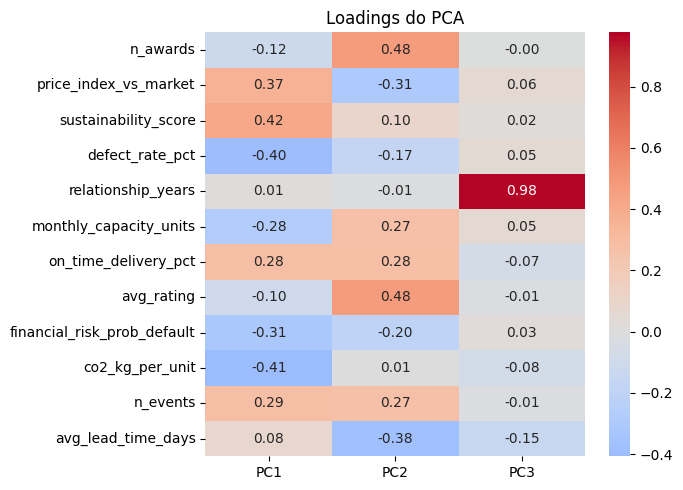

PCA significativas: ['avg_lead_time_days', 'avg_rating', 'co2_kg_per_unit', 'defect_rate_pct', 'financial_risk_prob_default', 'n_awards', 'price_index_vs_market', 'relationship_years', 'sustainability_score'] -> 9


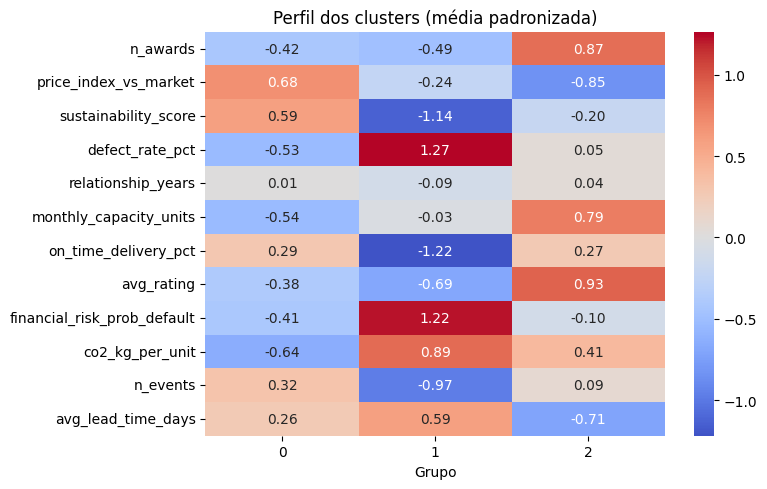

Seleção por cluster: ['avg_rating', 'co2_kg_per_unit', 'defect_rate_pct', 'financial_risk_prob_default', 'monthly_capacity_units', 'n_awards', 'on_time_delivery_pct', 'price_index_vs_market', 'sustainability_score'] -> 9


In [ ]:
loadings = pd.DataFrame(pca3.components_.T, columns=["PC1","PC2","PC3"], index=preds12)
plt.figure(figsize=(7,5)); sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Loadings do PCA"); plt.tight_layout(); plt.show()
pca_sig = sorted({v for pc in loadings.columns for v in loadings[pc].abs()[loadings[pc].abs()>=0.30].index})
print("PCA significativas:", pca_sig, f"-> {len(pca_sig)}")

Z = pd.DataFrame(StandardScaler().fit_transform(df[preds12]), columns=preds12, index=df.index)
Z["g"] = df["Supplier_Group"].values
perfil = Z.groupby("g")[preds12].mean()
plt.figure(figsize=(8,5)); sns.heatmap(perfil.T, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Perfil dos clusters (média padronizada)"); plt.xlabel("Grupo"); plt.tight_layout(); plt.show()
clust9 = sorted({v for g in perfil.index for v in perfil.loc[g].abs().sort_values(ascending=False).head(4).index})
print("Seleção por cluster:", clust9, f"-> {len(clust9)}")

**Resultado — assinatura dos componentes:** PC1 ≈ ambiental/qualidade; PC2 ≈ reputação (avaliação, prêmios);
PC3 ≈ tempo de relacionamento (quase sozinho, ~0,98). As listas do PCA e por cluster têm 9 variáveis e compartilham
7 — sinal de que essas são as mais informativas.

## 5.1 Os três perfis de fornecedor (insight de negócio)

O K-Means separou os fornecedores em 3 perfis com significado claro (valores padronizados: **+** acima da média, **−** abaixo):

| Perfil | Tamanho | Características marcantes | Interpretação |
|--------|:-------:|--------------------------|---------------|
| **Grupo 0 — Premium sustentável** | 198 | preço alto (+0,68), sustentável (+0,59), baixo CO₂ (−0,64), poucos defeitos (−0,53), capacidade baixa (−0,54) | caro e "verde", volume pequeno — bom para linhas de valor agregado / ESG |
| **Grupo 1 — Fornecedores de risco** | 78 | defeitos altos (+1,27), risco financeiro (+1,22), entrega ruim (−1,22), pouca sustentabilidade (−1,14) | exigem monitoramento próximo ou substituição |
| **Grupo 2 — Campeões competitivos** | 138 | bem avaliados (+0,93), muitos prêmios (+0,87), preço competitivo (−0,85), alta capacidade (+0,79) | candidatos naturais a fornecedores preferenciais |

**Uso prático:** priorizar o Grupo 2; usar o Grupo 0 em linhas premium/ESG; criar plano de contingência para o Grupo 1.

## 6. Definir os 7 cenários
**O que faz:** cada cenário é `(variáveis, usa_grupo?)`. Os pares 2↔3 e 4↔5 isolam o efeito do grupo.

In [ ]:
shap5 = ["financial_risk_prob_default","on_time_delivery_pct","n_awards","price_index_vs_market","avg_rating"]
cenarios = {
    "1-Original +grupo":       (feats16,  True),
    "2-PCA signif SEM grupo":  (pca_sig,  False),
    "3-PCA signif COM grupo":  (pca_sig,  True),
    "4-Cluster SEM grupo":     (clust9,   False),
    "5-Cluster COM grupo":     (clust9,   True),
    "6-Minimo SHAP +grupo":    (shap5,    True),
    "7-Controle (4 novas)":    (extras4,  False),
}
for n,(v,g) in cenarios.items(): print(f"{n}: {len(v)+(1 if g else 0)} variáveis{'  (com grupo)' if g else ''}")

1-Original +grupo: 17 variáveis  (com grupo)
2-PCA signif SEM grupo: 9 variáveis
3-PCA signif COM grupo: 10 variáveis  (com grupo)
4-Cluster SEM grupo: 9 variáveis
5-Cluster COM grupo: 10 variáveis  (com grupo)
6-Minimo SHAP +grupo: 6 variáveis  (com grupo)
7-Controle (4 novas): 4 variáveis


## 7. Motor: `rodar_cenario(...)`
**O que faz:** padroniza as numéricas + One-Hot no grupo, divide 75/25 estratificado, treina os 3 modelos num
`Pipeline` (sem vazamento de dados) e devolve acurácia, precisão e F1.

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import randint, loguniform, uniform
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    GridSearchCV
)
from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURAÇÕES GERAIS
# ============================================================

SEED = 42

# Métrica principal para selecionar modelos e hiperparâmetros
SCORING = "f1_macro"

CV_INTERNO = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# "rapido"   -> testes de funcionamento
# "completo" -> orçamento ampliado para análise final
#
# IMPORTANTE:
# "completo" não significa busca exaustiva.
# Significa executar o orçamento definido em n_iter.

MODO = "completo"

def n_it(padrao):
    return 10 if MODO == "rapido" else padrao

print("=" * 85)
print("CONFIGURAÇÃO DO EXPERIMENTO")
print("=" * 85)
print("Modo:", MODO)
print("Scoring:", SCORING)
print("CV interno:", CV_INTERNO.n_splits)
print("Random state:", SEED)


# ============================================================
# 2. MÉTRICAS DE AVALIAÇÃO
# ============================================================

# Média macro:
# cada classe tem o mesmo peso na média,
# independentemente da quantidade de observações.

METRICAS = {
    "Acc": (
        "Acurácia",
        lambda y, p: accuracy_score(y, p)
    ),
    "Prec": (
        "Precisão (macro)",
        lambda y, p: precision_score(
            y, p,
            average="macro",
            zero_division=0
        )
    ),
    "Rec": (
        "Recall (macro)",
        lambda y, p: recall_score(
            y, p,
            average="macro",
            zero_division=0
        )
    ),
    "F1": (
        "F1 (macro)",
        lambda y, p: f1_score(
            y, p,
            average="macro",
            zero_division=0
        )
    )
}


# ============================================================
# 3. CODIFICAÇÃO DO ALVO
# ============================================================

y_enc = LabelEncoder().fit(df[target])
Y = y_enc.transform(df[target])

print("\nCodificação do alvo:")
print(
    dict(
        zip(
            y_enc.classes_,
            range(len(y_enc.classes_))
        )
    )
)


# ============================================================
# 4. ESPAÇOS DE BUSCA DOS HIPERPARÂMETROS
# ============================================================

# Estratégias:
#
# grid:
#   GridSearchCV diretamente.
#
# random:
#   RandomizedSearchCV seguido de refinamento local.
#
# SVM:
#   Um único processo de otimização que considera
#   linear, rbf, poly e sigmoid.
#
#   Não existe treinamento separado de SVM linear.
#
#   O kernel vencedor será escolhido pelo melhor
#   F1-macro obtido na validação cruzada.
#
# XGBoost:
#   gbtree e gblinear participam da mesma busca.
#
# IMPORTANTE:
# O holdout não participa da escolha de modelos
# nem da seleção de hiperparâmetros.
#
# ============================================================

parametros = {

    # --------------------------------------------------------
    # KNN
    # --------------------------------------------------------

    "KNN": {
        "model": KNeighborsClassifier(),
        "busca": "grid",
        "params": {
            "n_neighbors": list(range(1, 31)),
            "weights": ["uniform", "distance"],
            "metric": [
                "euclidean",
                "manhattan",
                "chebyshev"
            ]
        }
    },

    # --------------------------------------------------------
    # NAIVE BAYES
    # --------------------------------------------------------

    "Naive Bayes": {
        "model": GaussianNB(),
        "busca": "grid",
        "params": {
            "var_smoothing": np.logspace(
                -12, -6, 100
            )
        }
    },

    # --------------------------------------------------------
    # REGRESSÃO LOGÍSTICA
    # --------------------------------------------------------

    "LogReg": {
        "model": LogisticRegression(
            max_iter=5000,
            random_state=SEED
        ),
        "busca": "grid",
        "params": {
            "C": np.logspace(-3, 3, 25)
        }
    },

    # --------------------------------------------------------
    # SVM - SELEÇÃO AUTOMÁTICA DO MELHOR KERNEL
    # --------------------------------------------------------

    "SVM": {
        "model": SVC(
            random_state=SEED,
            probability=False
        ),
        "busca": "random",
        "n_iter": 120,
        "refinar": ["C", "gamma"],

        # Cada dicionário corresponde a um kernel.
        #
        # RandomizedSearchCV considera os quatro
        # espaços de busca em uma única otimização.
        #
        # Não há SVM linear treinado separadamente.

        "params": [

            # Kernel LINEAR
            {
                "kernel": ["linear"],
                "C": loguniform(
                    1e-2, 1e2
                )
            },

            # Kernel RBF
            {
                "kernel": ["rbf"],
                "C": loguniform(
                    1e-2, 1e2
                ),
                "gamma": loguniform(
                    1e-4, 1e0
                )
            },

            # Kernel POLYNOMIAL
            {
                "kernel": ["poly"],
                "C": loguniform(
                    1e-2, 1e2
                ),
                "degree": [2, 3, 4],
                "gamma": loguniform(
                    1e-4, 1e0
                ),
                "coef0": uniform(
                    0, 1
                )
            },

            # Kernel SIGMOID
            {
                "kernel": ["sigmoid"],
                "C": loguniform(
                    1e-2, 1e2
                ),
                "gamma": loguniform(
                    1e-4, 1e0
                ),
                "coef0": uniform(
                    -1, 2
                )
            }
        ]
    },

    # --------------------------------------------------------
    # RANDOM FOREST
    # --------------------------------------------------------

    "Random Forest": {
        "model": RandomForestClassifier(
            random_state=SEED
        ),
        "busca": "random",
        "n_iter": 50,
        "refinar": [
            "n_estimators",
            "min_samples_split",
            "min_samples_leaf"
        ],
        "params": {
            "n_estimators": randint(100, 800),
            "criterion": [
                "gini",
                "entropy",
                "log_loss"
            ],
            "max_depth": [
                None, 5, 10, 20, 30
            ],
            "min_samples_split": randint(2, 20),
            "min_samples_leaf": randint(1, 10),
            "max_features": [
                "sqrt",
                "log2",
                None
            ]
        }
    },

    # --------------------------------------------------------
    # ADABOOST
    # --------------------------------------------------------

    "AdaBoost": {
        "model": AdaBoostClassifier(
            random_state=SEED
        ),
        "busca": "random",
        "n_iter": 40,
        "refinar": [
            "n_estimators",
            "learning_rate"
        ],
        "params": {
            "estimator": [
                DecisionTreeClassifier(
                    max_depth=d,
                    random_state=SEED
                )
                for d in (1, 2, 3)
            ],
            "n_estimators": randint(50, 500),
            "learning_rate": loguniform(
                1e-2, 2
            )
        }
    },

    # --------------------------------------------------------
    # XGBOOST
    # --------------------------------------------------------

    "XGBoost": {
        "model": XGBClassifier(
            random_state=SEED,
            n_jobs=1,
            verbosity=0,
            eval_metric="mlogloss"
        ),
        "busca": "random",
        "n_iter": 60,
        "refinar": [
            "learning_rate",
            "n_estimators",
            "max_depth"
        ],
        "params": [

            # gbtree
            {
                "booster": ["gbtree"],
                "n_estimators": randint(100, 600),
                "learning_rate": loguniform(
                    1e-2, 3e-1
                ),
                "max_depth": randint(2, 8),
                "subsample": uniform(0.6, 0.4),
                "colsample_bytree": uniform(0.6, 0.4),
                "reg_lambda": loguniform(
                    1e-1, 1e1
                )
            },

            # gblinear
            {
                "booster": ["gblinear"],
                "n_estimators": randint(100, 600),
                "learning_rate": loguniform(
                    1e-2, 5e-1
                ),
                "reg_lambda": loguniform(
                    1e-2, 1e1
                ),
                "reg_alpha": loguniform(
                    1e-3, 1e0
                )
            }
        ]
    }
}


# ============================================================
# 5. VARIANTES COMPARADAS
# ============================================================

# Comparações internas:
#
# SVM:
#   linear, rbf, poly, sigmoid
#
# XGBoost:
#   gbtree, gblinear
#
# O melhor é escolhido pela validação cruzada,
# não pelo desempenho no conjunto de teste.

VARIANTES = {
    "SVM": "kernel",
    "XGBoost": "booster"
}


# ============================================================
# 6. MODELOS BASE
# ============================================================

# Não há modelos independentes "SVM linear"
# ou "SVM rbf".
#
# Existe apenas "SVM", cujo kernel será otimizado.

models = {

    "KNN": KNeighborsClassifier(),

    "Naive Bayes": GaussianNB(),

    "LogReg": LogisticRegression(
        max_iter=5000,
        random_state=SEED
    ),

    "SVM": SVC(
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        random_state=SEED
    ),

    "AdaBoost": AdaBoostClassifier(
        random_state=SEED
    ),

    "XGBoost": XGBClassifier(
        random_state=SEED,
        n_jobs=1,
        verbosity=0,
        eval_metric="mlogloss"
    )
}

cv = CV_INTERNO


# ============================================================
# 7. CACHES DE RESULTADOS
# ============================================================

# Inicialização de novos caches para esta versão.
#
# Evita reutilizar automaticamente resultados antigos
# gerados por configurações diferentes.
#
# Ao executar esta célula, os resultados anteriores
# permanecem apenas se estiverem guardados em
# outras variáveis do notebook.

_store = {}
_cache = {}
_variantes = {}


# ============================================================
# 8. FUNÇÃO PARA PREFIXAR HIPERPARÂMETROS
# ============================================================

def prefixar(params):
    """
    Adiciona 'model__' aos hiperparâmetros.

    Aceita dicionário ou lista de dicionários.
    """

    if isinstance(params, dict):

        return {
            f"model__{k}": v
            for k, v in params.items()
        }

    return [
        prefixar(d)
        for d in params
    ]


# ============================================================
# 9. LIMITES PARA REFINAMENTO
# ============================================================

LIMITES = {
    "min_samples_split": (2, None),
    "min_samples_leaf": (1, None),
    "n_neighbors": (1, None),
    "n_estimators": (1, None),
    "max_depth": (1, None),
    "degree": (2, None),
    "C": (1e-8, None),
    "gamma": (1e-10, None),
    "learning_rate": (1e-8, None),
    "subsample": (0.1, 1.0),
    "colsample_bytree": (0.1, 1.0)
}


# ============================================================
# 10. REFINAMENTO LOCAL
# ============================================================

def montar_grid(melhor, refinar):
    """
    Constrói grade local em torno dos melhores
    hiperparâmetros encontrados na Random Search.

    Parâmetros não listados em 'refinar'
    permanecem fixos.

    O kernel ou booster vencedor também
    permanece fixo durante o refinamento.
    """

    grid = {}

    for p, v in melhor.items():

        k = p.replace("model__", "")

        lo, hi = LIMITES.get(
            k, (None, None)
        )

        numerico = (
            isinstance(
                v,
                (
                    int,
                    np.integer,
                    float,
                    np.floating
                )
            )
            and not isinstance(
                v,
                (bool, np.bool_)
            )
        )

        # Parâmetro fixo
        if (
            k not in refinar
            or not numerico
        ):

            grid[p] = [v]
            continue

        # Valores inteiros
        if isinstance(v, (int, np.integer)):

            v = int(v)

            passo = max(
                1,
                round(0.2 * v)
            )

            minimo = (
                1 if lo is None
                else lo
            )

            candidatos = {
                c
                for c in (
                    v - passo,
                    v,
                    v + passo
                )
                if (
                    c >= minimo
                    and (
                        hi is None
                        or c <= hi
                    )
                )
            }

            candidatos.add(v)

            grid[p] = sorted(candidatos)

        # Valores contínuos
        else:

            v = float(v)

            candidatos = {
                v / 3,
                v,
                v * 3
            }

            if lo is not None:

                candidatos = {
                    max(lo, c)
                    for c in candidatos
                }

            if hi is not None:

                candidatos = {
                    min(hi, c)
                    for c in candidatos
                }

            grid[p] = sorted(candidatos)

    return grid


# ============================================================
# 11. PRÉ-PROCESSAMENTO
# ============================================================

def montar_pre(nums, usar_grupo):
    """
    Padroniza variáveis numéricas.

    Quando usar_grupo=True, inclui
    Supplier_Group com OneHotEncoder.

    A transformação é ajustada apenas
    com os dados de treinamento dentro
    do Pipeline.
    """

    transformers = [
        (
            "num",
            StandardScaler(),
            nums
        )
    ]

    if usar_grupo:

        transformers.append(
            (
                "grp",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                ["Supplier_Group"]
            )
        )

    return ColumnTransformer(
        transformers,
        sparse_threshold=0
    )


# ============================================================
# 12. DIVISÃO DOS DADOS
# ============================================================

def preparar_split(nums, usar_grupo):
    """
    Divide os dados em:

    75% treinamento
    25% teste

    Divisão estratificada pelo alvo.
    """

    cols = list(nums) + (
        ["Supplier_Group"]
        if usar_grupo
        else []
    )

    pre = montar_pre(
        list(nums),
        usar_grupo
    )

    Xtr, Xte, ytr, yte = train_test_split(
        df[cols],
        Y,
        test_size=0.25,
        random_state=SEED,
        stratify=Y
    )

    return (
        cols,
        pre,
        Xtr,
        Xte,
        ytr,
        yte
    )


# ============================================================
# 13. RESULTADOS DAS VARIANTES
# ============================================================

def avaliar_variantes(
    pipe,
    rs,
    campo,
    Xtr,
    ytr,
    Xte=None,
    yte=None
):
    """
    Identifica a melhor configuração de cada variante
    utilizando exclusivamente a validação cruzada.

    Exemplo:
        SVM linear
        SVM rbf
        SVM poly
        SVM sigmoid

    Não executa outra busca de hiperparâmetros.

    Por padrão, não utiliza o holdout para
    comparar ou selecionar variantes.

    A avaliação no holdout fica reservada
    ao modelo final selecionado.
    """

    res = pd.DataFrame(
        rs.cv_results_
    )

    coluna = (
        f"param_model__{campo}"
    )

    saida = {}

    for variante, grupo in res.groupby(
        coluna,
        dropna=False
    ):

        grupo_valido = grupo.dropna(
            subset=["mean_test_score"]
        )

        if grupo_valido.empty:
            continue

        indice = (
            grupo_valido[
                "mean_test_score"
            ].idxmax()
        )

        params = res.loc[
            indice,
            "params"
        ]

        media_cv = float(
            res.loc[
                indice,
                "mean_test_score"
            ]
        )

        std_cv = float(
            res.loc[
                indice,
                "std_test_score"
            ]
        )

        saida[str(variante)] = {

            "n_testadas": len(grupo),

            "CV_score": round(
                media_cv, 4
            ),

            "CV_std": round(
                std_cv, 4
            ),

            "Params": params
        }

    return saida


# ============================================================
# 14. TABELA CONSOLIDADA DAS VARIANTES
# ============================================================

def tabela_variantes(modelo):
    """
    Retorna a comparação das variantes
    por cenário, utilizando F1-macro CV.
    """

    linhas = []

    for (nome, mn), saida in _variantes.items():

        if mn != modelo:
            continue

        for variante, d in saida.items():

            linhas.append({

                "Cenario": nome,

                "Variante": variante,

                **d
            })

    if not linhas:

        return pd.DataFrame(
            columns=[
                "Cenario",
                "Variante",
                "n_testadas",
                "CV_score",
                "CV_std",
                "Params"
            ]
        )

    return pd.DataFrame(
        linhas
    ).sort_values(
        [
            "Cenario",
            "CV_score"
        ],
        ascending=[
            True,
            False
        ]
    ).reset_index(drop=True)


# ============================================================
# 15. ESCOLHER MELHOR ESTIMADOR ENTRE RANDOM E GRID
# ============================================================

def selecionar_melhor_busca(rs, gs):
    """
    Compara os melhores resultados da Random
    Search e do refinamento local.

    A escolha usa exclusivamente o F1-macro CV.

    Se o refinamento não melhorar o resultado,
    mantém o vencedor da Random Search.
    """

    if (
        gs.best_score_
        >= rs.best_score_
    ):

        return (
            gs.best_estimator_,
            gs.best_params_,
            gs.best_score_,
            "Grid Refinamento"
        )

    return (
        rs.best_estimator_,
        rs.best_params_,
        rs.best_score_,
        "Random Search"
    )


# ============================================================
# 16. FUNÇÃO PRINCIPAL DE TREINAMENTO
# ============================================================

def rodar_cenario(
    nome,
    nums,
    usar_grupo,
    mostrar_matriz=False
):
    """
    Executa os sete algoritmos no cenário.

    Para SVM:
        otimiza os quatro kernels em uma busca;
        refina somente o kernel vencedor;
        mantém o melhor resultado por F1-macro CV.

    Para XGBoost:
        compara os boosters na mesma otimização.

    Holdout:
        utilizado exclusivamente para avaliação
        final de cada modelo selecionado.
    """

    (
        cols,
        pre,
        Xtr,
        Xte,
        ytr,
        yte
    ) = preparar_split(
        nums,
        usar_grupo
    )

    if (
        pd.Series(ytr).value_counts().min()
        < CV_INTERNO.n_splits
    ):

        raise ValueError(
            "Há menos observações por classe no treino "
            "do que o número de folds do CV interno."
        )

    linha = {
        "Cenario": nome,
        "n_vars": len(cols)
    }

    print("\n" + "=" * 85)
    print("CENÁRIO:", nome)
    print("=" * 85)

    print("Variáveis:", len(cols))
    print("Treino:", len(Xtr))
    print("Teste:", len(Xte))

    for mn, info in parametros.items():

        print("\n" + "-" * 70)
        print("MODELO:", mn)
        print("-" * 70)

        pipe = Pipeline([
            (
                "pre",
                clone(pre)
            ),
            (
                "model",
                clone(info["model"])
            )
        ])

        rs = None

        # ----------------------------------------------------
        # BUSCA ALEATÓRIA
        # ----------------------------------------------------

        if info["busca"] == "random":

            print(
                "Random Search:",
                n_it(
                    info.get("n_iter", 50)
                ),
                "configurações"
            )

            rs = RandomizedSearchCV(

                estimator=pipe,

                param_distributions=prefixar(
                    info["params"]
                ),

                n_iter=n_it(
                    info.get("n_iter", 50)
                ),

                cv=CV_INTERNO,

                scoring=SCORING,

                random_state=SEED,

                n_jobs=-1,

                refit=True,

                return_train_score=False,

                error_score="raise"
            )

            rs.fit(
                Xtr,
                ytr
            )

            print(
                "Melhor Random CV:",
                round(
                    rs.best_score_, 4
                )
            )

            print(
                "Melhores parâmetros Random:",
                rs.best_params_
            )

            # -----------------------------------------------
            # COMPARAR KERNELS / BOOSTERS APENAS PELO CV
            # -----------------------------------------------

            if mn in VARIANTES:

                _variantes[(nome, mn)] = (
                    avaliar_variantes(
                        pipe,
                        rs,
                        VARIANTES[mn],
                        Xtr,
                        ytr
                    )
                )

                tabela_v = (
                    pd.DataFrame(
                        _variantes[
                            (nome, mn)
                        ]
                    )
                    .T
                )

                if not tabela_v.empty:

                    tabela_v = (
                        tabela_v.drop(
                            columns=["Params"],
                            errors="ignore"
                        )
                    )

                    print(
                        "\nComparação interna:",
                        VARIANTES[mn]
                    )

                    display(
                        tabela_v.sort_values(
                            "CV_score",
                            ascending=False
                        )
                    )

            # -----------------------------------------------
            # REFINAMENTO LOCAL
            # -----------------------------------------------

            grid_local = montar_grid(
                rs.best_params_,
                info.get("refinar", [])
            )

            gs = GridSearchCV(

                estimator=pipe,

                param_grid=grid_local,

                cv=CV_INTERNO,

                scoring=SCORING,

                n_jobs=-1,

                refit=True,

                error_score="raise"
            )

            gs.fit(
                Xtr,
                ytr
            )

            # -----------------------------------------------
            # SELECIONAR MELHOR RESULTADO
            # -----------------------------------------------

            (
                melhor,
                melhores_params,
                melhor_cv,
                origem_melhor
            ) = selecionar_melhor_busca(
                rs,
                gs
            )

        # ----------------------------------------------------
        # GRID SEARCH DIRETO
        # ----------------------------------------------------

        else:

            print("Grid Search direto.")

            gs = GridSearchCV(

                estimator=pipe,

                param_grid=prefixar(
                    info["params"]
                ),

                cv=CV_INTERNO,

                scoring=SCORING,

                n_jobs=-1,

                refit=True,

                error_score="raise"
            )

            gs.fit(
                Xtr,
                ytr
            )

            melhor = gs.best_estimator_

            melhores_params = (
                gs.best_params_
            )

            melhor_cv = (
                gs.best_score_
            )

            origem_melhor = "Grid Search"

        # ----------------------------------------------------
        # PREDIÇÃO NO HOLDOUT
        # ----------------------------------------------------

        pred = melhor.predict(
            Xte
        )

        # ----------------------------------------------------
        # MÉTRICAS
        # ----------------------------------------------------

        for sigla, (_, fn) in METRICAS.items():

            linha[
                f"{mn}_{sigla}"
            ] = round(
                fn(yte, pred),
                4
            )

        linha[
            f"{mn}_CV"
        ] = round(
            melhor_cv,
            4
        )

        linha[
            f"{mn}_Random_Params"
        ] = (
            rs.best_params_
            if rs is not None
            else None
        )

        linha[
            f"{mn}_Grid_Params"
        ] = gs.best_params_

        linha[
            f"{mn}_Best_Params"
        ] = melhores_params

        linha[
            f"{mn}_Selecao"
        ] = origem_melhor

        # ----------------------------------------------------
        # KERNEL VENCEDOR DO SVM
        # ----------------------------------------------------

        if mn == "SVM":

            kernel_escolhido = (
                melhor
                .named_steps["model"]
                .kernel
            )

            linha[
                "SVM_Kernel"
            ] = kernel_escolhido

            print("\nKERNEL SVM VENCEDOR:")
            print(kernel_escolhido)

            print(
                "F1-macro CV:",
                round(melhor_cv, 4)
            )

            print(
                "F1-macro Holdout:",
                linha["SVM_F1"]
            )

        # ----------------------------------------------------
        # BOOSTER VENCEDOR DO XGBOOST
        # ----------------------------------------------------

        if mn == "XGBoost":

            booster_escolhido = (
                melhor
                .named_steps["model"]
                .get_params()
                .get("booster")
            )

            linha[
                "XGBoost_Booster"
            ] = booster_escolhido

            print("\nBOOSTER XGBOOST VENCEDOR:")
            print(booster_escolhido)

        # ----------------------------------------------------
        # ARMAZENAR RESULTADOS
        # ----------------------------------------------------

        _store[(nome, mn)] = {

            "pipeline_final": melhor,

            "X_train": Xtr.copy(),

            "y_train": np.asarray(ytr),

            "X_test": Xte.copy(),

            "y_test": np.asarray(yte),

            "pred": np.asarray(pred),

            "random_best_params": (
                rs.best_params_
                if rs is not None
                else None
            ),

            "grid_best_params": (
                gs.best_params_
            ),

            "best_params": (
                melhores_params
            ),

            "random_cv_score": (
                rs.best_score_
                if rs is not None
                else None
            ),

            "grid_cv_score": (
                gs.best_score_
            ),

            "best_cv_score": (
                melhor_cv
            ),

            "selection_source": (
                origem_melhor
            ),

            "scoring": SCORING,

            "features": list(cols),

            "kernel": (
                melhor.named_steps["model"].kernel
                if mn == "SVM"
                else None
            )
        }

        # ----------------------------------------------------
        # RESUMO DO MODELO
        # ----------------------------------------------------

        print("\nResultado selecionado:")
        print("Origem:", origem_melhor)
        print("F1-macro CV:", round(melhor_cv, 4))
        print("F1-macro Holdout:", linha[f"{mn}_F1"])
        print("Hiperparâmetros:", melhores_params)

        # ----------------------------------------------------
        # MATRIZ INDIVIDUAL OPCIONAL
        # ----------------------------------------------------

        if mostrar_matriz:

            ordem = list(
                y_enc.transform(classes)
            )

            cm = confusion_matrix(
                yte,
                pred,
                labels=ordem
            )

            plt.figure(
                figsize=(5, 4)
            )

            sns.heatmap(
                cm,
                annot=True,
                fmt="d",
                cmap="Blues",
                xticklabels=classes,
                yticklabels=classes
            )

            plt.title(
                f"{nome} - {mn}"
            )

            plt.xlabel("Previsto")
            plt.ylabel("Real")

            plt.tight_layout()
            plt.show()

    # --------------------------------------------------------
    # GUARDAR RESULTADO DO CENÁRIO
    # --------------------------------------------------------

    _cache[nome] = linha

    print("\n" + "=" * 85)
    print("CENÁRIO FINALIZADO:", nome)
    print("=" * 85)

    return linha


# ============================================================
# 17. OBTER CENÁRIO
# ============================================================

def obter_cenario(nome):
    """
    Executa o cenário somente quando
    ainda não existe resultado em cache.

    Requer o dicionário 'cenarios'
    definido anteriormente no notebook.
    """

    if nome not in cenarios:

        raise KeyError(
            f"Cenário não encontrado: {nome}"
        )

    # Evita cache parcial ou incompatível

    modelos_esperados = list(
        parametros.keys()
    )

    cache_valido = (
        nome in _cache
        and all(
            (nome, mn) in _store
            for mn in modelos_esperados
        )
    )

    if not cache_valido:

        nums, usar_grupo = (
            cenarios[nome]
        )

        _cache[nome] = rodar_cenario(
            nome,
            nums,
            usar_grupo
        )

    return _cache[nome]


# ============================================================
# 18. VISUALIZAR RESULTADOS DO CENÁRIO
# ============================================================

def mostrar_cenario(nome):
    """
    Exibe:

    1. Tabela comparativa dos algoritmos.
    2. Kernel SVM selecionado.
    3. Booster XGBoost selecionado.
    4. Comparação interna por F1-macro CV.
    5. Matrizes de confusão.
    6. Ranking dos algoritmos pelo F1-macro CV.
    """

    linha = obter_cenario(nome)

    ms = list(
        parametros.keys()
    )

    # --------------------------------------------------------
    # TABELA DE MÉTRICAS
    # --------------------------------------------------------

    resumo = pd.DataFrame(

        {
            sig: [
                linha[f"{m}_{sig}"]
                for m in ms
            ]

            for sig in (
                list(METRICAS) + ["CV"]
            )
        },

        index=ms
    )

    resumo.index.name = "Modelo"

    print("\n" + "=" * 85)
    print("RESULTADOS:", nome)
    print("=" * 85)

    print(
        "Número de variáveis:",
        linha["n_vars"]
    )

    print("\nMÉTRICAS DOS MODELOS:")

    display(
        resumo.round(4)
    )

    # --------------------------------------------------------
    # MODELOS E VARIANTES SELECIONADOS
    # --------------------------------------------------------

    print("\nKERNEL SVM SELECIONADO:")
    print(
        linha.get(
            "SVM_Kernel"
        )
    )

    print("\nBOOSTER XGBOOST SELECIONADO:")
    print(
        linha.get(
            "XGBoost_Booster"
        )
    )

    # --------------------------------------------------------
    # COMPARAÇÃO DOS KERNELS / BOOSTERS
    # --------------------------------------------------------

    for modelo_v, campo in VARIANTES.items():

        saida = _variantes.get(
            (nome, modelo_v)
        )

        if not saida:
            continue

        tv = pd.DataFrame(
            saida
        ).T

        tv = tv.drop(
            columns=["Params"],
            errors="ignore"
        )

        tv.index.name = campo

        tv = tv.sort_values(
            "CV_score",
            ascending=False
        )

        print(
            f"\n{modelo_v}: "
            f"COMPARAÇÃO POR {campo.upper()}"
        )

        display(tv)

    # --------------------------------------------------------
    # MATRIZES DE CONFUSÃO
    # --------------------------------------------------------

    ordem = list(
        y_enc.transform(
            classes
        )
    )

    ncols = 4

    nrows = int(
        np.ceil(
            len(ms) / ncols
        )
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            4 * ncols,
            3.5 * nrows
        )
    )

    axes = np.atleast_1d(
        axes
    ).ravel()

    for ax, mn in zip(
        axes,
        ms
    ):

        d = _store[
            (nome, mn)
        ]

        cm = confusion_matrix(
            d["y_test"],
            d["pred"],
            labels=ordem
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            xticklabels=classes,
            yticklabels=classes,
            ax=ax
        )

        if mn == "SVM":

            titulo = (
                f"SVM ({linha['SVM_Kernel']})"
            )

        elif mn == "XGBoost":

            titulo = (
                f"XGBoost "
                f"({linha['XGBoost_Booster']})"
            )

        else:

            titulo = mn

        ax.set_title(
            titulo
        )

        ax.set_xlabel(
            "Previsto"
        )

        ax.set_ylabel(
            "Real"
        )

    for ax in axes[len(ms):]:

        ax.axis("off")

    fig.suptitle(
        f"Matrizes de confusão - {nome}",
        fontsize=14
    )

    fig.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # RANKING DOS MODELOS
    # --------------------------------------------------------

    # Classificação por F1-macro da validação
    # cruzada, não pelo desempenho no holdout.

    ranking_modelos = (
        resumo
        .sort_values(
            "CV",
            ascending=False
        )
    )

    print("\nRANKING DOS MODELOS POR F1-MACRO CV:")

    display(
        ranking_modelos.round(4)
    )

    melhor_modelo = (
        ranking_modelos.index[0]
    )

    print("\nMELHOR MODELO POR VALIDAÇÃO CRUZADA:")
    print(melhor_modelo)

    print(
        "F1-macro CV:",
        ranking_modelos.iloc[0]["CV"]
    )

    return resumo


# ============================================================
# 19. FUNÇÃO PARA CONSULTAR O SVM VENCEDOR
# ============================================================

def obter_melhor_svm(nome_cenario):
    """
    Recupera diretamente o melhor SVM
    armazenado para o cenário.

    A seleção do kernel já foi feita
    na otimização original.

    Não executa novos treinamentos
    se o cenário estiver em cache.
    """

    obter_cenario(nome_cenario)

    chave = (
        nome_cenario,
        "SVM"
    )

    resultado = _store[chave]

    pipeline = resultado[
        "pipeline_final"
    ]

    modelo_svm = pipeline.named_steps[
        "model"
    ]

    print("\n" + "=" * 85)
    print("MELHOR SVM DO CENÁRIO")
    print("=" * 85)

    print("Cenário:", nome_cenario)

    print(
        "Kernel:",
        modelo_svm.kernel
    )

    print(
        "Parâmetros:",
        resultado["best_params"]
    )

    print(
        "F1-macro CV:",
        round(
            resultado["best_cv_score"],
            4
        )
    )

    return pipeline


# ============================================================
# 20. TABELA GERAL DOS CENÁRIOS
# ============================================================

def consolidar_resultados():
    """
    Consolida resultados dos cenários
    já executados e armazenados em cache.
    """

    if not _cache:

        print(
            "Nenhum cenário foi executado."
        )

        return pd.DataFrame()

    linhas = list(
        _cache.values()
    )

    tabela = pd.DataFrame(
        linhas
    )

    return tabela


# ============================================================
# 21. RESUMO FINAL DA CONFIGURAÇÃO
# ============================================================

print("\n" + "=" * 85)
print("MOTOR DE CLASSIFICAÇÃO CONFIGURADO")
print("=" * 85)

print("""
MODELOS:

1. KNN
2. Naive Bayes
3. Logistic Regression
4. SVM
5. Random Forest
6. AdaBoost
7. XGBoost

SVM:
- linear
- rbf
- poly
- sigmoid

Os kernels são avaliados dentro de
uma única estratégia de otimização.

Não existe SVM linear independente.

SELEÇÃO:
- F1-macro
- StratifiedKFold
- 5 folds
- Random Search
- Refinamento local

AVALIAÇÃO:
- Accuracy
- Precision macro
- Recall macro
- F1 macro
- Matriz de confusão

ARMAZENAMENTO:
- _store
- _cache
- _variantes

FUNÇÕES:
- rodar_cenario()
- obter_cenario()
- mostrar_cenario()
- tabela_variantes()
- obter_melhor_svm()
- consolidar_resultados()

MODO:
""")

print(MODO)

print("\nIterações de Random Search:")
print("SVM:", n_it(120))
print("Random Forest:", n_it(50))
print("AdaBoost:", n_it(40))
print("XGBoost:", n_it(60))

print("\nMotor pronto para executar os cenários.")


CONFIGURAÇÃO DO EXPERIMENTO
Modo: completo
Scoring: f1_macro
CV interno: 5
Random state: 42

Codificação do alvo:
{'AVERAGE': 0, 'GOOD': 1, 'POOR': 2}

MOTOR DE CLASSIFICAÇÃO CONFIGURADO

MODELOS:

1. KNN
2. Naive Bayes
3. Logistic Regression
4. SVM
5. Random Forest
6. AdaBoost
7. XGBoost

SVM:
- linear
- rbf
- poly
- sigmoid

Os kernels são avaliados dentro de
uma única estratégia de otimização.

Não existe SVM linear independente.

SELEÇÃO:
- F1-macro
- StratifiedKFold
- 5 folds
- Random Search
- Refinamento local

AVALIAÇÃO:
- Accuracy
- Precision macro
- Recall macro
- F1 macro
- Matriz de confusão

ARMAZENAMENTO:
- _store
- _cache
- _variantes

FUNÇÕES:
- rodar_cenario()
- obter_cenario()
- mostrar_cenario()
- tabela_variantes()
- obter_melhor_svm()
- consolidar_resultados()

MODO:

completo

Iterações de Random Search:
SVM: 120
Random Forest: 50
AdaBoost: 40
XGBoost: 60

Motor pronto para executar os cenários.


## 8. Rodar cada cenário
Cada teste traz a **tabela das variáveis**, o **motivo**, o **esperado** e o **resultado**.

### Teste 1 — Original (todas as 16 variáveis) + grupo

**Motivo:** é a **linha de base** — os demais cenários são comparados com ela.

**Esperado:** bom desempenho, mas modelo complexo (difícil de explicar).

**Variáveis participantes (17):**

| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `n_awards` | Nº de prêmios/reconhecimentos | mais = maturidade e reputação |
| 2 | `price_index_vs_market` | Preço frente ao mercado | menor = mais competitivo |
| 3 | `sustainability_score` | Índice de sustentabilidade (ESG) | maior = melhor |
| 4 | `defect_rate_pct` | Taxa de defeitos (%) | menor = mais qualidade |
| 5 | `relationship_years` | Anos de relacionamento | maior = confiança/estabilidade |
| 6 | `monthly_capacity_units` | Capacidade mensal de produção | maior = mais escala |
| 7 | `on_time_delivery_pct` | Entregas no prazo (%) | maior = mais confiável |
| 8 | `avg_rating` | Avaliação média do fornecedor | maior = melhor percepção |
| 9 | `financial_risk_prob_default` | Probabilidade de inadimplência | maior = mais risco financeiro |
| 10 | `co2_kg_per_unit` | Emissão de CO₂ por unidade | menor = mais sustentável |
| 11 | `n_events` | Nº de eventos/interações | maior = mais engajamento |
| 12 | `avg_lead_time_days` | Lead time médio (dias) | menor = mais ágil |
| 13 | `responsiveness_score` | Capacidade de resposta | maior = melhor comunicação |
| 14 | `innovation_score` | Índice de inovação | maior = mais inovador |
| 15 | `avg_offer_price_index` | Preço médio das propostas | menor = proposta mais competitiva |
| 16 | `avg_offer_lead_time` | Prazo médio das propostas | menor = prazo prometido menor |
| 17 | `Supplier_Group` | Grupo do fornecedor (0/1/2) | perfil do PCA+K-Means; vira 3 colunas sim/não (One-Hot) |


CENÁRIO: 1-Original +grupo
Variáveis: 17
Treino: 310
Teste: 104

----------------------------------------------------------------------
MODELO: KNN
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.7268
F1-macro Holdout: 0.6508
Hiperparâmetros: {'model__metric': 'manhattan', 'model__n_neighbors': 9, 'model__weights': 'uniform'}

----------------------------------------------------------------------
MODELO: Naive Bayes
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.5752
F1-macro Holdout: 0.5684
Hiperparâmetros: {'model__var_smoothing': np.float64(5.722367659350221e-07)}

----------------------------------------------------------------------
MODELO: LogReg
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Searc

,n_testadas,CV_score,CV_std
linear,28,0.9522,0.0273
rbf,33,0.8937,0.0385
sigmoid,32,0.8761,0.0228
poly,27,0.8625,0.0375



KERNEL SVM VENCEDOR:
linear
F1-macro CV: 0.9522
F1-macro Holdout: 0.9431

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.9522
F1-macro Holdout: 0.9431
Hiperparâmetros: {'model__C': 27.129089558470042, 'model__kernel': 'linear'}

----------------------------------------------------------------------
MODELO: Random Forest
----------------------------------------------------------------------
Random Search: 50 configurações
Melhor Random CV: 0.8059
Melhores parâmetros Random: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 6, 'model__n_estimators': 589}

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8185
F1-macro Holdout: 0.7758
Hiperparâmetros: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 589}

---------------------------------------------------

,n_testadas,CV_score,CV_std
gblinear,38,0.8789,0.0273
gbtree,22,0.8045,0.0299



BOOSTER XGBOOST VENCEDOR:
gblinear

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8789
F1-macro Holdout: 0.8764
Hiperparâmetros: {'model__booster': 'gblinear', 'model__learning_rate': 0.2972554739324683, 'model__n_estimators': 90, 'model__reg_alpha': np.float64(0.0017570436113703504), 'model__reg_lambda': np.float64(0.010364648739254174)}

CENÁRIO FINALIZADO: 1-Original +grupo

RESULTADOS: 1-Original +grupo
Número de variáveis: 17

MÉTRICAS DOS MODELOS:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.6442,0.6982,0.6424,0.6508,0.7268
Naive Bayes,0.5962,0.6137,0.6034,0.5684,0.5752
LogReg,0.9423,0.9468,0.9425,0.9431,0.9425
SVM,0.9423,0.9468,0.9425,0.9431,0.9522
Random Forest,0.7692,0.7916,0.7698,0.7758,0.8185
AdaBoost,0.8269,0.8770,0.8263,0.8322,0.8199
XGBoost,0.8750,0.8826,0.8744,0.8764,0.8789



KERNEL SVM SELECIONADO:
linear

BOOSTER XGBOOST SELECIONADO:
gblinear

SVM: COMPARAÇÃO POR KERNEL


,n_testadas,CV_score,CV_std
kernel,,,
linear,28,0.9522,0.0273
rbf,33,0.8937,0.0385
sigmoid,32,0.8761,0.0228
poly,27,0.8625,0.0375



XGBoost: COMPARAÇÃO POR BOOSTER


,n_testadas,CV_score,CV_std
booster,,,
gblinear,38,0.8789,0.0273
gbtree,22,0.8045,0.0299


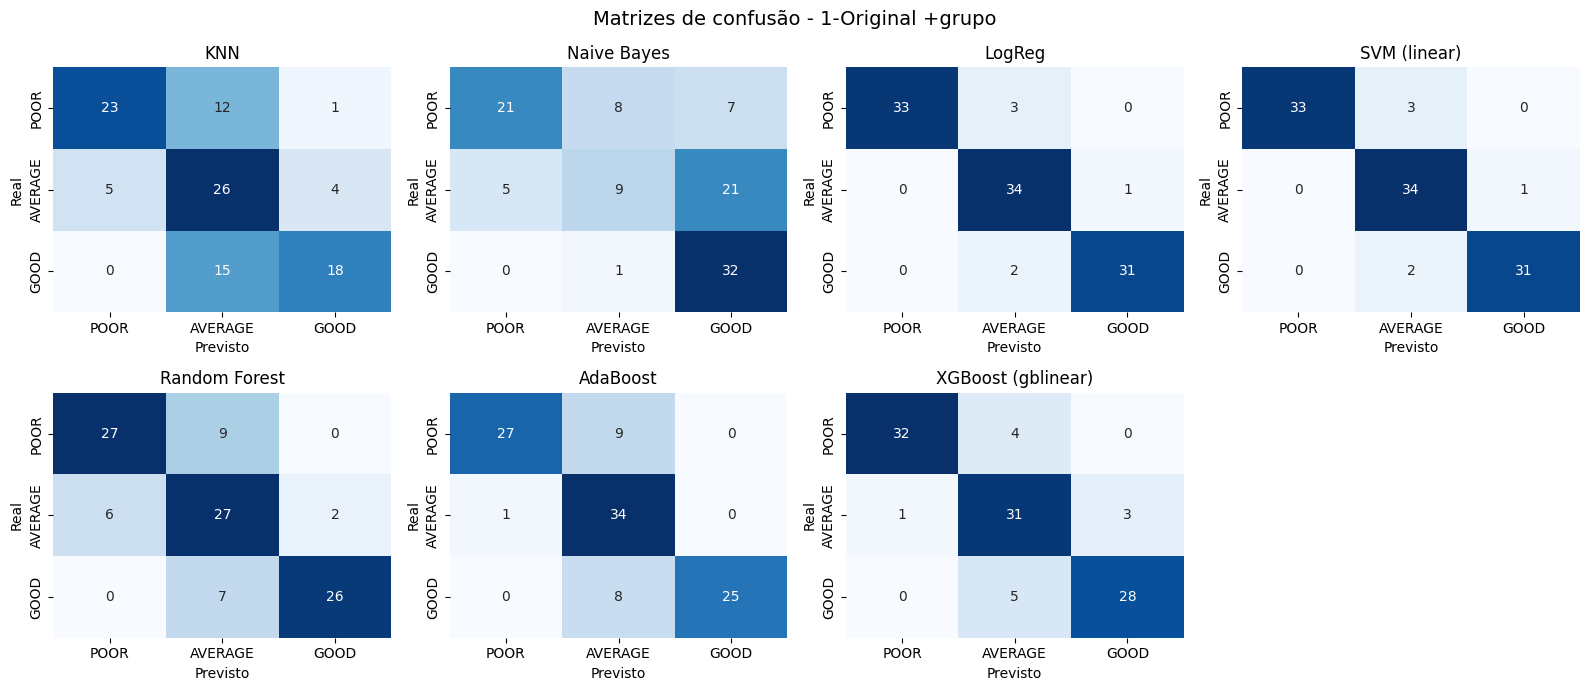


RANKING DOS MODELOS POR F1-MACRO CV:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
SVM,0.9423,0.9468,0.9425,0.9431,0.9522
LogReg,0.9423,0.9468,0.9425,0.9431,0.9425
XGBoost,0.8750,0.8826,0.8744,0.8764,0.8789
AdaBoost,0.8269,0.8770,0.8263,0.8322,0.8199
Random Forest,0.7692,0.7916,0.7698,0.7758,0.8185
KNN,0.6442,0.6982,0.6424,0.6508,0.7268
Naive Bayes,0.5962,0.6137,0.6034,0.5684,0.5752



MELHOR MODELO POR VALIDAÇÃO CRUZADA:
SVM
F1-macro CV: 0.9522


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.6442,0.6982,0.6424,0.6508,0.7268
Naive Bayes,0.5962,0.6137,0.6034,0.5684,0.5752
LogReg,0.9423,0.9468,0.9425,0.9431,0.9425
SVM,0.9423,0.9468,0.9425,0.9431,0.9522
Random Forest,0.7692,0.7916,0.7698,0.7758,0.8185
AdaBoost,0.8269,0.8770,0.8263,0.8322,0.8199
XGBoost,0.8750,0.8826,0.8744,0.8764,0.8789


In [ ]:
mostrar_cenario("1-Original +grupo")

Resultado...

### Teste 2 — Variáveis fortes do PCA, SEM grupo

**Motivo:** testar se poucas variáveis (as fortes do PCA), sem o grupo, já bastam. Serve de "antes" na comparação do grupo.

**Esperado:** cair pouco em relação ao Teste 1.

**Variáveis participantes (9):**

| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `avg_lead_time_days` | Lead time médio (dias) | menor = mais ágil |
| 2 | `avg_rating` | Avaliação média do fornecedor | maior = melhor percepção |
| 3 | `co2_kg_per_unit` | Emissão de CO₂ por unidade | menor = mais sustentável |
| 4 | `defect_rate_pct` | Taxa de defeitos (%) | menor = mais qualidade |
| 5 | `financial_risk_prob_default` | Probabilidade de inadimplência | maior = mais risco financeiro |
| 6 | `n_awards` | Nº de prêmios/reconhecimentos | mais = maturidade e reputação |
| 7 | `price_index_vs_market` | Preço frente ao mercado | menor = mais competitivo |
| 8 | `relationship_years` | Anos de relacionamento | maior = confiança/estabilidade |
| 9 | `sustainability_score` | Índice de sustentabilidade (ESG) | maior = melhor |


CENÁRIO: 2-PCA signif SEM grupo
Variáveis: 9
Treino: 310
Teste: 104

----------------------------------------------------------------------
MODELO: KNN
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.7269
F1-macro Holdout: 0.7008
Hiperparâmetros: {'model__metric': 'euclidean', 'model__n_neighbors': 28, 'model__weights': 'distance'}

----------------------------------------------------------------------
MODELO: Naive Bayes
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.6568
F1-macro Holdout: 0.6161
Hiperparâmetros: {'model__var_smoothing': np.float64(1e-12)}

----------------------------------------------------------------------
MODELO: LogReg
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro

,n_testadas,CV_score,CV_std
rbf,33,0.8237,0.0515
sigmoid,32,0.8187,0.0537
linear,28,0.8168,0.0592
poly,27,0.8075,0.0543



KERNEL SVM VENCEDOR:
rbf
F1-macro CV: 0.8237
F1-macro Holdout: 0.8492

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8237
F1-macro Holdout: 0.8492
Hiperparâmetros: {'model__C': 13.16746532693615, 'model__gamma': 0.036993598999597505, 'model__kernel': 'rbf'}

----------------------------------------------------------------------
MODELO: Random Forest
----------------------------------------------------------------------
Random Search: 50 configurações
Melhor Random CV: 0.776
Melhores parâmetros Random: {'model__criterion': 'log_loss', 'model__max_depth': 10, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 661}

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.7786
F1-macro Holdout: 0.7653
Hiperparâmetros: {'model__criterion': 'log_loss', 'model__max_depth': 10, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__min_samples_split': 4, 'model__n_estimators': 661}

---------

,n_testadas,CV_score,CV_std
gblinear,38,0.8115,0.0568
gbtree,22,0.7936,0.0426



BOOSTER XGBOOST VENCEDOR:
gblinear

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8157
F1-macro Holdout: 0.8095
Hiperparâmetros: {'model__booster': 'gblinear', 'model__learning_rate': 0.0269327468130445, 'model__n_estimators': 500, 'model__reg_alpha': np.float64(0.004637921903458032), 'model__reg_lambda': np.float64(0.02288738114460097)}

CENÁRIO FINALIZADO: 2-PCA signif SEM grupo

RESULTADOS: 2-PCA signif SEM grupo
Número de variáveis: 9

MÉTRICAS DOS MODELOS:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.6923,0.7510,0.6918,0.7008,0.7269
Naive Bayes,0.6058,0.6674,0.6048,0.6161,0.6568
LogReg,0.8365,0.8464,0.8376,0.8393,0.8251
SVM,0.8462,0.8578,0.8472,0.8492,0.8237
Random Forest,0.7596,0.7822,0.7597,0.7653,0.7786
AdaBoost,0.7500,0.7912,0.7509,0.7574,0.7789
XGBoost,0.8077,0.8146,0.8091,0.8095,0.8157



KERNEL SVM SELECIONADO:
rbf

BOOSTER XGBOOST SELECIONADO:
gblinear

SVM: COMPARAÇÃO POR KERNEL


,n_testadas,CV_score,CV_std
kernel,,,
rbf,33,0.8237,0.0515
sigmoid,32,0.8187,0.0537
linear,28,0.8168,0.0592
poly,27,0.8075,0.0543



XGBoost: COMPARAÇÃO POR BOOSTER


,n_testadas,CV_score,CV_std
booster,,,
gblinear,38,0.8115,0.0568
gbtree,22,0.7936,0.0426


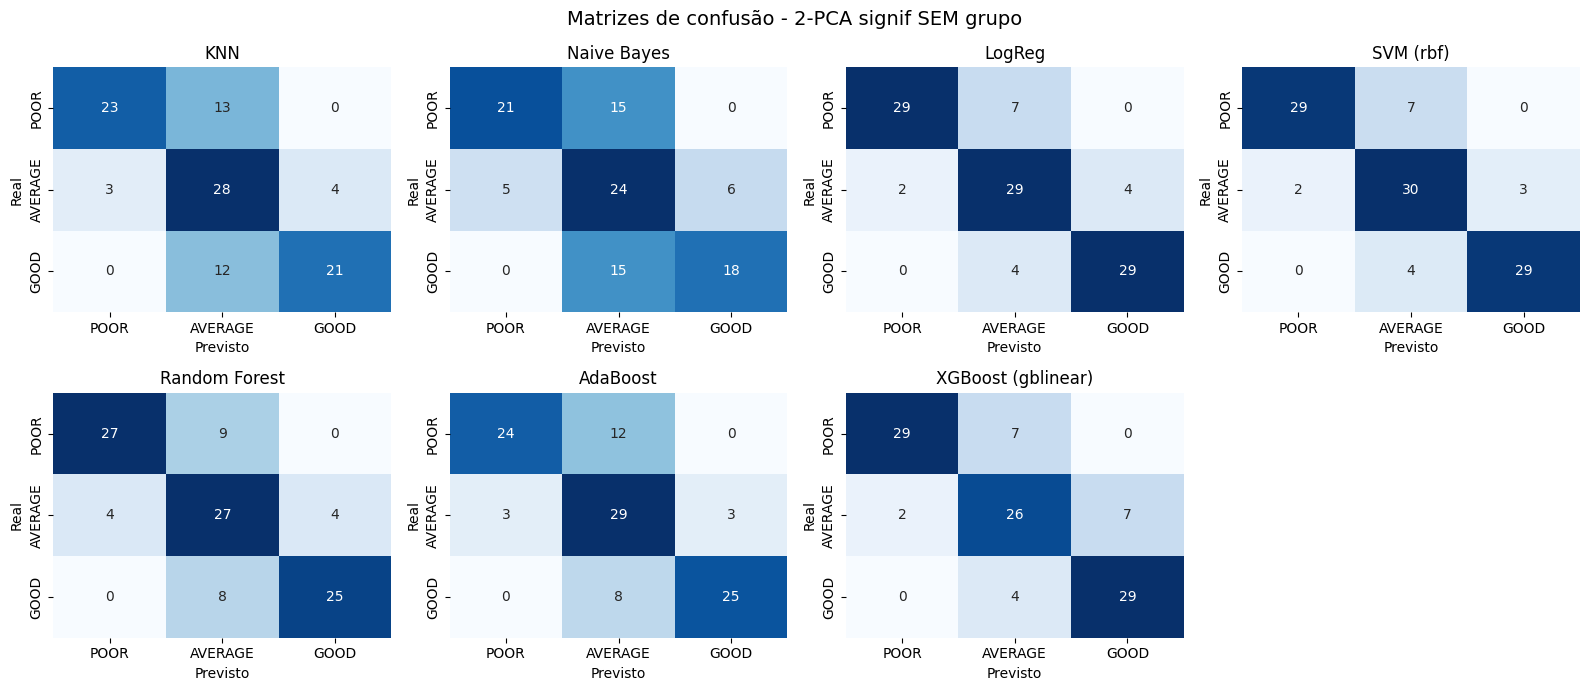


RANKING DOS MODELOS POR F1-MACRO CV:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
LogReg,0.8365,0.8464,0.8376,0.8393,0.8251
SVM,0.8462,0.8578,0.8472,0.8492,0.8237
XGBoost,0.8077,0.8146,0.8091,0.8095,0.8157
AdaBoost,0.7500,0.7912,0.7509,0.7574,0.7789
Random Forest,0.7596,0.7822,0.7597,0.7653,0.7786
KNN,0.6923,0.7510,0.6918,0.7008,0.7269
Naive Bayes,0.6058,0.6674,0.6048,0.6161,0.6568



MELHOR MODELO POR VALIDAÇÃO CRUZADA:
LogReg
F1-macro CV: 0.8251


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.6923,0.7510,0.6918,0.7008,0.7269
Naive Bayes,0.6058,0.6674,0.6048,0.6161,0.6568
LogReg,0.8365,0.8464,0.8376,0.8393,0.8251
SVM,0.8462,0.8578,0.8472,0.8492,0.8237
Random Forest,0.7596,0.7822,0.7597,0.7653,0.7786
AdaBoost,0.7500,0.7912,0.7509,0.7574,0.7789
XGBoost,0.8077,0.8146,0.8091,0.8095,0.8157


In [ ]:
mostrar_cenario("2-PCA signif SEM grupo")

Resultado...

### Teste 3 — Variáveis fortes do PCA, COM grupo

**Motivo:** pegar o Teste 2 e **só adicionar o grupo** — assim qualquer mudança é efeito exclusivo do grupo.

**Esperado:** medir o ganho do grupo.

**Variáveis participantes (10):**

| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `avg_lead_time_days` | Lead time médio (dias) | menor = mais ágil |
| 2 | `avg_rating` | Avaliação média do fornecedor | maior = melhor percepção |
| 3 | `co2_kg_per_unit` | Emissão de CO₂ por unidade | menor = mais sustentável |
| 4 | `defect_rate_pct` | Taxa de defeitos (%) | menor = mais qualidade |
| 5 | `financial_risk_prob_default` | Probabilidade de inadimplência | maior = mais risco financeiro |
| 6 | `n_awards` | Nº de prêmios/reconhecimentos | mais = maturidade e reputação |
| 7 | `price_index_vs_market` | Preço frente ao mercado | menor = mais competitivo |
| 8 | `relationship_years` | Anos de relacionamento | maior = confiança/estabilidade |
| 9 | `sustainability_score` | Índice de sustentabilidade (ESG) | maior = melhor |
| 10 | `Supplier_Group` | Grupo do fornecedor (0/1/2) | perfil do PCA+K-Means; vira 3 colunas sim/não (One-Hot) |


CENÁRIO: 3-PCA signif COM grupo
Variáveis: 10
Treino: 310
Teste: 104

----------------------------------------------------------------------
MODELO: KNN
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.7099
F1-macro Holdout: 0.6805
Hiperparâmetros: {'model__metric': 'euclidean', 'model__n_neighbors': 14, 'model__weights': 'distance'}

----------------------------------------------------------------------
MODELO: Naive Bayes
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.4992
F1-macro Holdout: 0.4412
Hiperparâmetros: {'model__var_smoothing': np.float64(8.697490026177835e-07)}

----------------------------------------------------------------------
MODELO: LogReg
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Gri

,n_testadas,CV_score,CV_std
linear,28,0.8401,0.0515
rbf,33,0.8276,0.0671
sigmoid,32,0.82,0.0506
poly,27,0.8163,0.0552



KERNEL SVM VENCEDOR:
linear
F1-macro CV: 0.8401
F1-macro Holdout: 0.8483

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8401
F1-macro Holdout: 0.8483
Hiperparâmetros: {'model__C': 1.0245858939867325, 'model__kernel': 'linear'}

----------------------------------------------------------------------
MODELO: Random Forest
----------------------------------------------------------------------
Random Search: 50 configurações
Melhor Random CV: 0.7926
Melhores parâmetros Random: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 6, 'model__n_estimators': 589}

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.7988
F1-macro Holdout: 0.764
Hiperparâmetros: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 6, 'model__n_estimators': 471}

----------------------------------------------------

,n_testadas,CV_score,CV_std
gblinear,38,0.8028,0.0665
gbtree,22,0.7932,0.0417



BOOSTER XGBOOST VENCEDOR:
gblinear

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8028
F1-macro Holdout: 0.8294
Hiperparâmetros: {'model__booster': 'gblinear', 'model__learning_rate': 0.0807982404391335, 'model__n_estimators': 334, 'model__reg_alpha': np.float64(0.004637921903458032), 'model__reg_lambda': np.float64(0.02288738114460097)}

CENÁRIO FINALIZADO: 3-PCA signif COM grupo

RESULTADOS: 3-PCA signif COM grupo
Número de variáveis: 10

MÉTRICAS DOS MODELOS:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.6731,0.7095,0.6724,0.6805,0.7099
Naive Bayes,0.5096,0.4816,0.5179,0.4412,0.4992
LogReg,0.8462,0.8575,0.8463,0.8489,0.8405
SVM,0.8462,0.8533,0.8469,0.8483,0.8401
Random Forest,0.7596,0.7774,0.7597,0.7640,0.7988
AdaBoost,0.7019,0.7320,0.7011,0.7088,0.7843
XGBoost,0.8269,0.8355,0.8281,0.8294,0.8028



KERNEL SVM SELECIONADO:
linear

BOOSTER XGBOOST SELECIONADO:
gblinear

SVM: COMPARAÇÃO POR KERNEL


,n_testadas,CV_score,CV_std
kernel,,,
linear,28,0.8401,0.0515
rbf,33,0.8276,0.0671
sigmoid,32,0.82,0.0506
poly,27,0.8163,0.0552



XGBoost: COMPARAÇÃO POR BOOSTER


,n_testadas,CV_score,CV_std
booster,,,
gblinear,38,0.8028,0.0665
gbtree,22,0.7932,0.0417


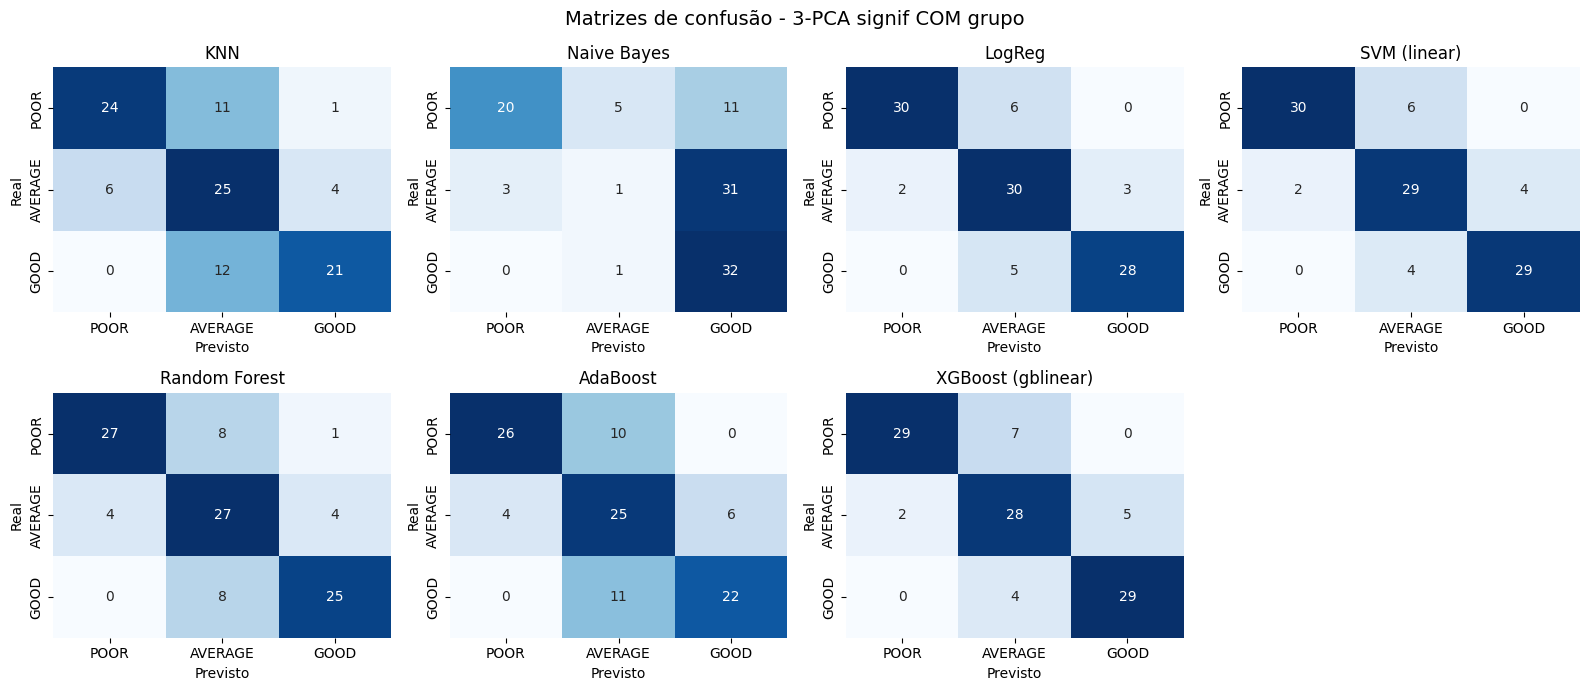


RANKING DOS MODELOS POR F1-MACRO CV:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
LogReg,0.8462,0.8575,0.8463,0.8489,0.8405
SVM,0.8462,0.8533,0.8469,0.8483,0.8401
XGBoost,0.8269,0.8355,0.8281,0.8294,0.8028
Random Forest,0.7596,0.7774,0.7597,0.7640,0.7988
AdaBoost,0.7019,0.7320,0.7011,0.7088,0.7843
KNN,0.6731,0.7095,0.6724,0.6805,0.7099
Naive Bayes,0.5096,0.4816,0.5179,0.4412,0.4992



MELHOR MODELO POR VALIDAÇÃO CRUZADA:
LogReg
F1-macro CV: 0.8405


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.6731,0.7095,0.6724,0.6805,0.7099
Naive Bayes,0.5096,0.4816,0.5179,0.4412,0.4992
LogReg,0.8462,0.8575,0.8463,0.8489,0.8405
SVM,0.8462,0.8533,0.8469,0.8483,0.8401
Random Forest,0.7596,0.7774,0.7597,0.7640,0.7988
AdaBoost,0.7019,0.7320,0.7011,0.7088,0.7843
XGBoost,0.8269,0.8355,0.8281,0.8294,0.8028


In [ ]:
mostrar_cenario("3-PCA signif COM grupo")

**Resultado:** A

### Teste 4 — Seleção por cluster, SEM grupo

**Motivo:** escolher as variáveis por outro critério — as que mais **definem cada grupo** — em vez do PCA. Testa se o método de seleção importa.

**Esperado:** parecido com o Teste 2.

**Variáveis participantes (9):**

| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `avg_rating` | Avaliação média do fornecedor | maior = melhor percepção |
| 2 | `co2_kg_per_unit` | Emissão de CO₂ por unidade | menor = mais sustentável |
| 3 | `defect_rate_pct` | Taxa de defeitos (%) | menor = mais qualidade |
| 4 | `financial_risk_prob_default` | Probabilidade de inadimplência | maior = mais risco financeiro |
| 5 | `monthly_capacity_units` | Capacidade mensal de produção | maior = mais escala |
| 6 | `n_awards` | Nº de prêmios/reconhecimentos | mais = maturidade e reputação |
| 7 | `on_time_delivery_pct` | Entregas no prazo (%) | maior = mais confiável |
| 8 | `price_index_vs_market` | Preço frente ao mercado | menor = mais competitivo |
| 9 | `sustainability_score` | Índice de sustentabilidade (ESG) | maior = melhor |


CENÁRIO: 4-Cluster SEM grupo
Variáveis: 9
Treino: 310
Teste: 104

----------------------------------------------------------------------
MODELO: KNN
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.7919
F1-macro Holdout: 0.7368
Hiperparâmetros: {'model__metric': 'euclidean', 'model__n_neighbors': 13, 'model__weights': 'distance'}

----------------------------------------------------------------------
MODELO: Naive Bayes
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.6532
F1-macro Holdout: 0.6405
Hiperparâmetros: {'model__var_smoothing': np.float64(1e-12)}

----------------------------------------------------------------------
MODELO: LogReg
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV

,n_testadas,CV_score,CV_std
linear,28,0.9683,0.0103
rbf,33,0.9267,0.0131
sigmoid,32,0.9077,0.0187
poly,27,0.8794,0.0273



KERNEL SVM VENCEDOR:
linear
F1-macro CV: 0.9683
F1-macro Holdout: 0.962

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.9683
F1-macro Holdout: 0.962
Hiperparâmetros: {'model__C': 95.10471384597577, 'model__kernel': 'linear'}

----------------------------------------------------------------------
MODELO: Random Forest
----------------------------------------------------------------------
Random Search: 50 configurações
Melhor Random CV: 0.8118
Melhores parâmetros Random: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 6, 'model__n_estimators': 589}

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8183
F1-macro Holdout: 0.7431
Hiperparâmetros: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 7, 'model__n_estimators': 471}

------------------------------------------------------

,n_testadas,CV_score,CV_std
gblinear,38,0.9141,0.0297
gbtree,22,0.8259,0.0506



BOOSTER XGBOOST VENCEDOR:
gblinear

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.9141
F1-macro Holdout: 0.8867
Hiperparâmetros: {'model__booster': 'gblinear', 'model__learning_rate': 0.2972554739324683, 'model__n_estimators': 112, 'model__reg_alpha': np.float64(0.0017570436113703504), 'model__reg_lambda': np.float64(0.010364648739254174)}

CENÁRIO FINALIZADO: 4-Cluster SEM grupo

RESULTADOS: 4-Cluster SEM grupo
Número de variáveis: 9

MÉTRICAS DOS MODELOS:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.7308,0.7712,0.7288,0.7368,0.7919
Naive Bayes,0.6346,0.6908,0.6323,0.6405,0.6532
LogReg,0.9615,0.9658,0.9621,0.9624,0.9745
SVM,0.9615,0.9658,0.9613,0.9620,0.9683
Random Forest,0.7404,0.7481,0.7401,0.7431,0.8183
AdaBoost,0.8462,0.8696,0.8460,0.8499,0.8298
XGBoost,0.8846,0.8949,0.8847,0.8867,0.9141



KERNEL SVM SELECIONADO:
linear

BOOSTER XGBOOST SELECIONADO:
gblinear

SVM: COMPARAÇÃO POR KERNEL


,n_testadas,CV_score,CV_std
kernel,,,
linear,28,0.9683,0.0103
rbf,33,0.9267,0.0131
sigmoid,32,0.9077,0.0187
poly,27,0.8794,0.0273



XGBoost: COMPARAÇÃO POR BOOSTER


,n_testadas,CV_score,CV_std
booster,,,
gblinear,38,0.9141,0.0297
gbtree,22,0.8259,0.0506


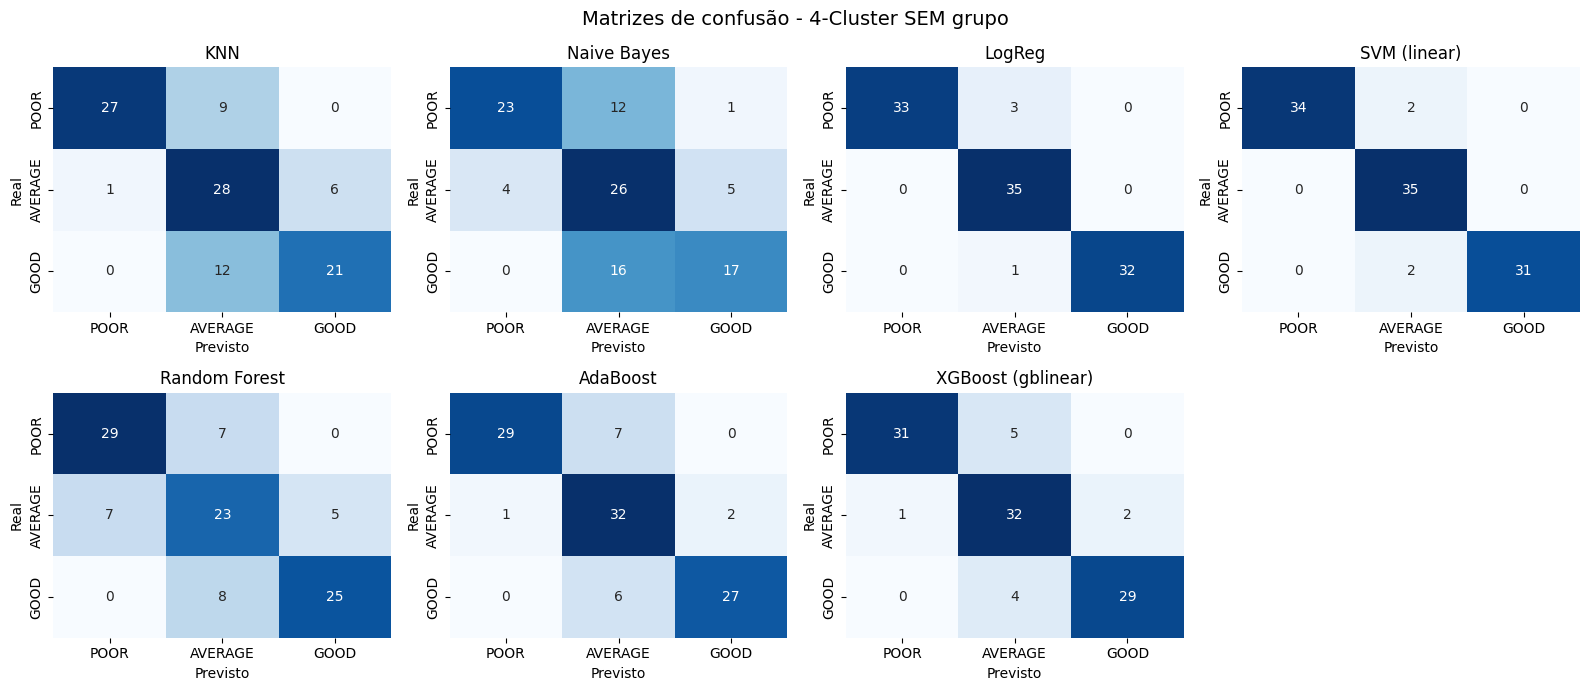


RANKING DOS MODELOS POR F1-MACRO CV:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
LogReg,0.9615,0.9658,0.9621,0.9624,0.9745
SVM,0.9615,0.9658,0.9613,0.9620,0.9683
XGBoost,0.8846,0.8949,0.8847,0.8867,0.9141
AdaBoost,0.8462,0.8696,0.8460,0.8499,0.8298
Random Forest,0.7404,0.7481,0.7401,0.7431,0.8183
KNN,0.7308,0.7712,0.7288,0.7368,0.7919
Naive Bayes,0.6346,0.6908,0.6323,0.6405,0.6532



MELHOR MODELO POR VALIDAÇÃO CRUZADA:
LogReg
F1-macro CV: 0.9745


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.7308,0.7712,0.7288,0.7368,0.7919
Naive Bayes,0.6346,0.6908,0.6323,0.6405,0.6532
LogReg,0.9615,0.9658,0.9621,0.9624,0.9745
SVM,0.9615,0.9658,0.9613,0.9620,0.9683
Random Forest,0.7404,0.7481,0.7401,0.7431,0.8183
AdaBoost,0.8462,0.8696,0.8460,0.8499,0.8298
XGBoost,0.8846,0.8949,0.8847,0.8867,0.9141


In [ ]:
mostrar_cenario("4-Cluster SEM grupo")

**Resultado:** A

### Teste 5 — Seleção por cluster, COM grupo

**Motivo:** é o par do Teste 4 — verifica se o efeito do grupo se repete nesta outra seleção.

**Esperado:** medir de novo o ganho do grupo.

**Variáveis participantes (10):**

| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `avg_rating` | Avaliação média do fornecedor | maior = melhor percepção |
| 2 | `co2_kg_per_unit` | Emissão de CO₂ por unidade | menor = mais sustentável |
| 3 | `defect_rate_pct` | Taxa de defeitos (%) | menor = mais qualidade |
| 4 | `financial_risk_prob_default` | Probabilidade de inadimplência | maior = mais risco financeiro |
| 5 | `monthly_capacity_units` | Capacidade mensal de produção | maior = mais escala |
| 6 | `n_awards` | Nº de prêmios/reconhecimentos | mais = maturidade e reputação |
| 7 | `on_time_delivery_pct` | Entregas no prazo (%) | maior = mais confiável |
| 8 | `price_index_vs_market` | Preço frente ao mercado | menor = mais competitivo |
| 9 | `sustainability_score` | Índice de sustentabilidade (ESG) | maior = melhor |
| 10 | `Supplier_Group` | Grupo do fornecedor (0/1/2) | perfil do PCA+K-Means; vira 3 colunas sim/não (One-Hot) |


CENÁRIO: 5-Cluster COM grupo
Variáveis: 10
Treino: 310
Teste: 104

----------------------------------------------------------------------
MODELO: KNN
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.7625
F1-macro Holdout: 0.7257
Hiperparâmetros: {'model__metric': 'manhattan', 'model__n_neighbors': 5, 'model__weights': 'uniform'}

----------------------------------------------------------------------
MODELO: Naive Bayes
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.52
F1-macro Holdout: 0.4522
Hiperparâmetros: {'model__var_smoothing': np.float64(1e-06)}

----------------------------------------------------------------------
MODELO: LogReg
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0

,n_testadas,CV_score,CV_std
linear,28,0.9618,0.0164
rbf,33,0.9265,0.0241
sigmoid,32,0.8952,0.0308
poly,27,0.8855,0.0303



KERNEL SVM VENCEDOR:
linear
F1-macro CV: 0.9684
F1-macro Holdout: 0.9624

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.9684
F1-macro Holdout: 0.9624
Hiperparâmetros: {'model__C': 227.3843986004403, 'model__kernel': 'linear'}

----------------------------------------------------------------------
MODELO: Random Forest
----------------------------------------------------------------------
Random Search: 50 configurações
Melhor Random CV: 0.8033
Melhores parâmetros Random: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 6, 'model__n_estimators': 589}

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8097
F1-macro Holdout: 0.7838
Hiperparâmetros: {'model__criterion': 'gini', 'model__max_depth': 10, 'model__max_features': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 7, 'model__n_estimators': 589}

----------------------------------------------------

,n_testadas,CV_score,CV_std
gblinear,38,0.9082,0.0414
gbtree,22,0.8275,0.0388



BOOSTER XGBOOST VENCEDOR:
gblinear

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.9082
F1-macro Holdout: 0.8773
Hiperparâmetros: {'model__booster': 'gblinear', 'model__learning_rate': 0.2972554739324683, 'model__n_estimators': 90, 'model__reg_alpha': np.float64(0.0017570436113703504), 'model__reg_lambda': np.float64(0.010364648739254174)}

CENÁRIO FINALIZADO: 5-Cluster COM grupo

RESULTADOS: 5-Cluster COM grupo
Número de variáveis: 10

MÉTRICAS DOS MODELOS:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.7212,0.7397,0.7204,0.7257,0.7625
Naive Bayes,0.5096,0.4855,0.5182,0.4522,0.5200
LogReg,0.9615,0.9658,0.9621,0.9624,0.9654
SVM,0.9615,0.9658,0.9621,0.9624,0.9684
Random Forest,0.7788,0.7991,0.7782,0.7838,0.8097
AdaBoost,0.8077,0.8594,0.8067,0.8134,0.8291
XGBoost,0.8750,0.8880,0.8746,0.8773,0.9082



KERNEL SVM SELECIONADO:
linear

BOOSTER XGBOOST SELECIONADO:
gblinear

SVM: COMPARAÇÃO POR KERNEL


,n_testadas,CV_score,CV_std
kernel,,,
linear,28,0.9618,0.0164
rbf,33,0.9265,0.0241
sigmoid,32,0.8952,0.0308
poly,27,0.8855,0.0303



XGBoost: COMPARAÇÃO POR BOOSTER


,n_testadas,CV_score,CV_std
booster,,,
gblinear,38,0.9082,0.0414
gbtree,22,0.8275,0.0388


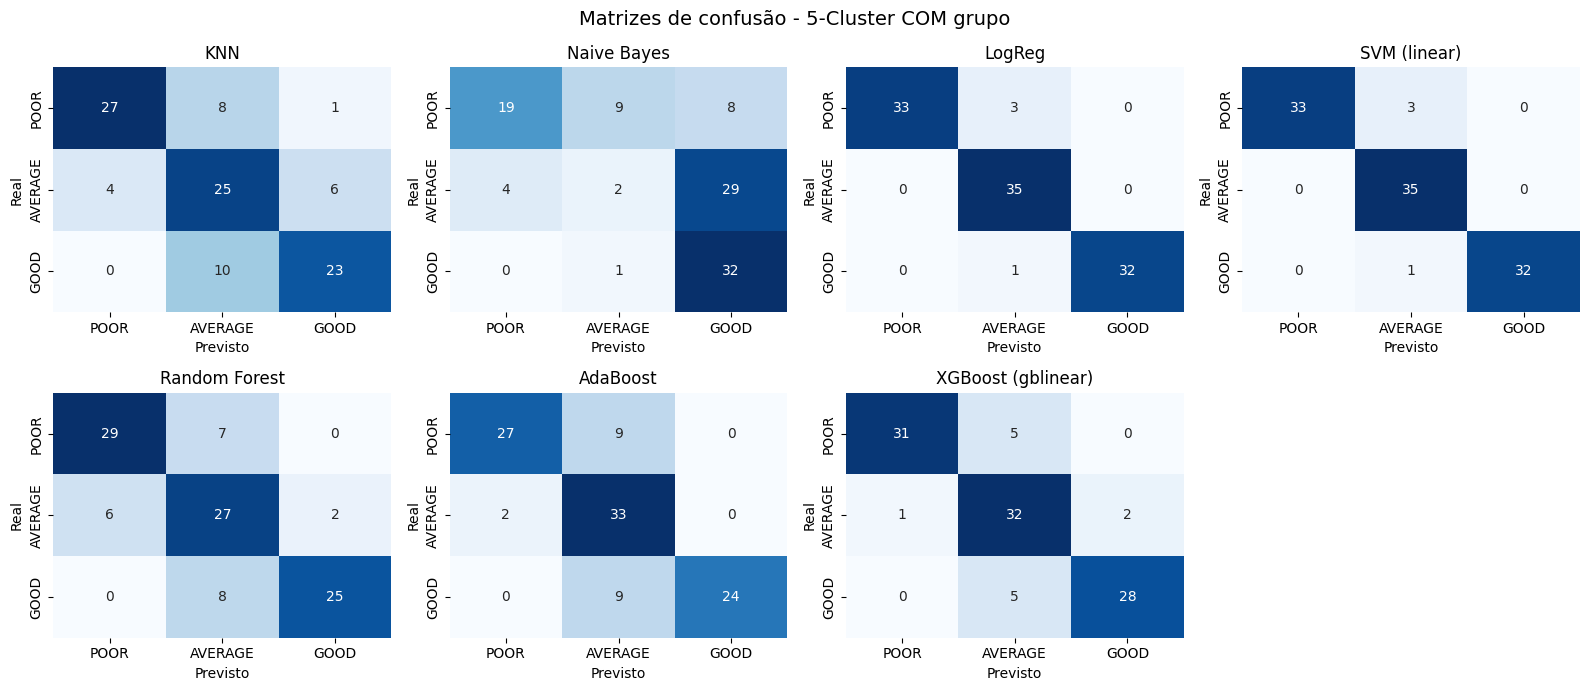


RANKING DOS MODELOS POR F1-MACRO CV:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
SVM,0.9615,0.9658,0.9621,0.9624,0.9684
LogReg,0.9615,0.9658,0.9621,0.9624,0.9654
XGBoost,0.8750,0.8880,0.8746,0.8773,0.9082
AdaBoost,0.8077,0.8594,0.8067,0.8134,0.8291
Random Forest,0.7788,0.7991,0.7782,0.7838,0.8097
KNN,0.7212,0.7397,0.7204,0.7257,0.7625
Naive Bayes,0.5096,0.4855,0.5182,0.4522,0.5200



MELHOR MODELO POR VALIDAÇÃO CRUZADA:
SVM
F1-macro CV: 0.9684


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.7212,0.7397,0.7204,0.7257,0.7625
Naive Bayes,0.5096,0.4855,0.5182,0.4522,0.5200
LogReg,0.9615,0.9658,0.9621,0.9624,0.9654
SVM,0.9615,0.9658,0.9621,0.9624,0.9684
Random Forest,0.7788,0.7991,0.7782,0.7838,0.8097
AdaBoost,0.8077,0.8594,0.8067,0.8134,0.8291
XGBoost,0.8750,0.8880,0.8746,0.8773,0.9082


In [ ]:
mostrar_cenario("5-Cluster COM grupo")

**Resultado:** RF 0,769 → 0,788. Ganho pequeno, na mesma direção do par PCA.

### Teste 6 — Modelo mínimo (top do SHAP) + grupo

**Motivo:** qual o **mínimo** de variáveis para um bom resultado? Usa as 5 mais influentes do SHAP + grupo. Se funcionar, é o mais fácil de explicar.

**Esperado:** competitivo com pouquíssimas variáveis.

**Variáveis participantes (6):**

| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `financial_risk_prob_default` | Probabilidade de inadimplência | maior = mais risco financeiro |
| 2 | `on_time_delivery_pct` | Entregas no prazo (%) | maior = mais confiável |
| 3 | `n_awards` | Nº de prêmios/reconhecimentos | mais = maturidade e reputação |
| 4 | `price_index_vs_market` | Preço frente ao mercado | menor = mais competitivo |
| 5 | `avg_rating` | Avaliação média do fornecedor | maior = melhor percepção |
| 6 | `Supplier_Group` | Grupo do fornecedor (0/1/2) | perfil do PCA+K-Means; vira 3 colunas sim/não (One-Hot) |


CENÁRIO: 6-Minimo SHAP +grupo
Variáveis: 6
Treino: 310
Teste: 104

----------------------------------------------------------------------
MODELO: KNN
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.8025
F1-macro Holdout: 0.8498
Hiperparâmetros: {'model__metric': 'euclidean', 'model__n_neighbors': 20, 'model__weights': 'distance'}

----------------------------------------------------------------------
MODELO: Naive Bayes
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.4771
F1-macro Holdout: 0.4452
Hiperparâmetros: {'model__var_smoothing': np.float64(1e-06)}

----------------------------------------------------------------------
MODELO: LogReg
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro C

,n_testadas,CV_score,CV_std
rbf,33,0.8453,0.0402
poly,27,0.8401,0.0364
linear,28,0.8381,0.0672
sigmoid,32,0.8297,0.0334



KERNEL SVM VENCEDOR:
rbf
F1-macro CV: 0.8453
F1-macro Holdout: 0.8783

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8453
F1-macro Holdout: 0.8783
Hiperparâmetros: {'model__C': 13.16746532693615, 'model__gamma': 0.036993598999597505, 'model__kernel': 'rbf'}

----------------------------------------------------------------------
MODELO: Random Forest
----------------------------------------------------------------------
Random Search: 50 configurações
Melhor Random CV: 0.7995
Melhores parâmetros Random: {'model__criterion': 'gini', 'model__max_depth': 20, 'model__max_features': None, 'model__min_samples_leaf': 3, 'model__min_samples_split': 15, 'model__n_estimators': 769}

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8027
F1-macro Holdout: 0.7839
Hiperparâmetros: {'model__criterion': 'gini', 'model__max_depth': 20, 'model__max_features': None, 'model__min_samples_leaf': 4, 'model__min_samples_split': 18, 'model__n_estimators': 923}

------------------

,n_testadas,CV_score,CV_std
gblinear,38,0.8257,0.0523
gbtree,22,0.8244,0.0316



BOOSTER XGBOOST VENCEDOR:
gblinear

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.8257
F1-macro Holdout: 0.8671
Hiperparâmetros: {'model__booster': 'gblinear', 'model__learning_rate': 0.2972554739324683, 'model__n_estimators': 90, 'model__reg_alpha': np.float64(0.0017570436113703504), 'model__reg_lambda': np.float64(0.010364648739254174)}

CENÁRIO FINALIZADO: 6-Minimo SHAP +grupo

RESULTADOS: 6-Minimo SHAP +grupo
Número de variáveis: 6

MÉTRICAS DOS MODELOS:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.8462,0.8725,0.8477,0.8498,0.8025
Naive Bayes,0.5385,0.4287,0.5463,0.4452,0.4771
LogReg,0.8846,0.8952,0.8856,0.8869,0.8348
SVM,0.8750,0.8944,0.8757,0.8783,0.8453
Random Forest,0.7788,0.7960,0.7790,0.7839,0.8027
AdaBoost,0.7500,0.7762,0.7513,0.7565,0.8134
XGBoost,0.8654,0.8739,0.8674,0.8671,0.8257



KERNEL SVM SELECIONADO:
rbf

BOOSTER XGBOOST SELECIONADO:
gblinear

SVM: COMPARAÇÃO POR KERNEL


,n_testadas,CV_score,CV_std
kernel,,,
rbf,33,0.8453,0.0402
poly,27,0.8401,0.0364
linear,28,0.8381,0.0672
sigmoid,32,0.8297,0.0334



XGBoost: COMPARAÇÃO POR BOOSTER


,n_testadas,CV_score,CV_std
booster,,,
gblinear,38,0.8257,0.0523
gbtree,22,0.8244,0.0316


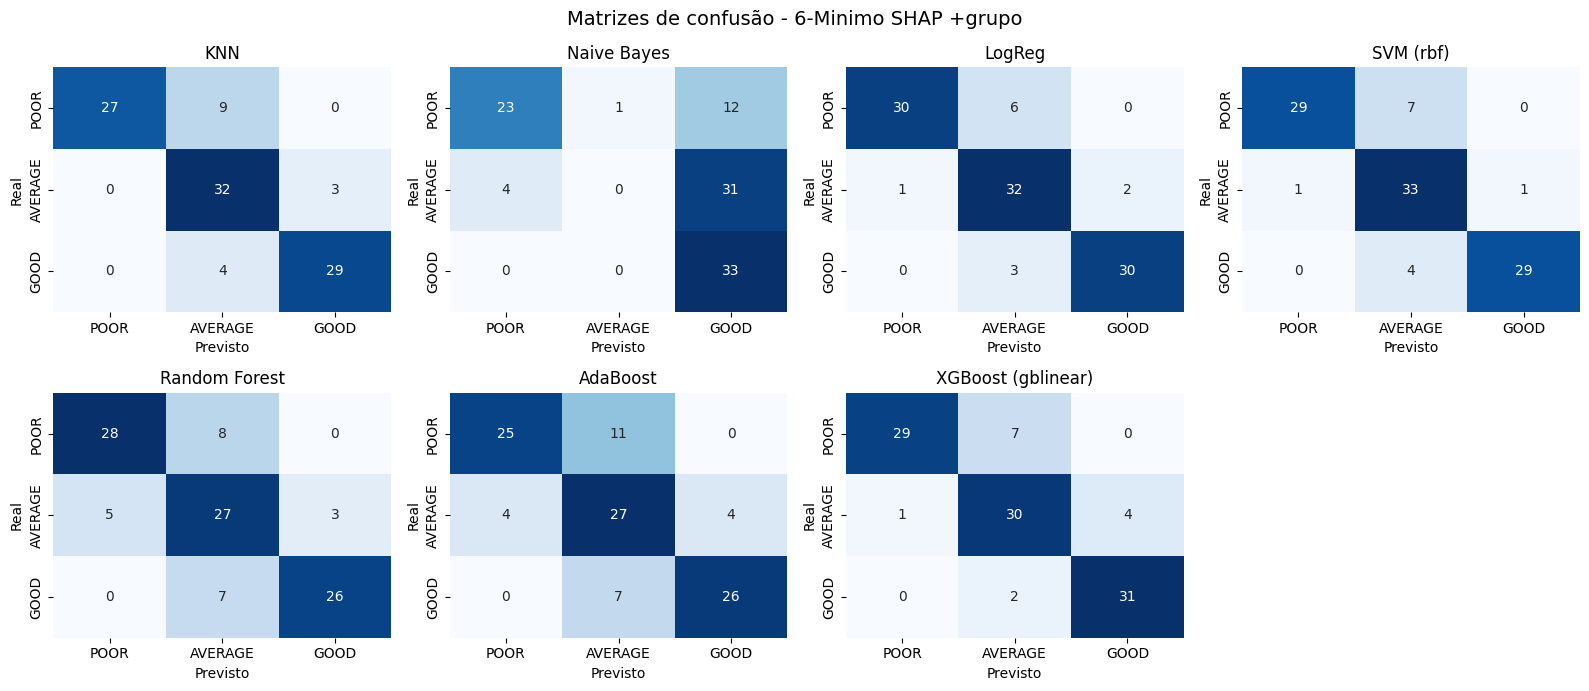


RANKING DOS MODELOS POR F1-MACRO CV:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
SVM,0.8750,0.8944,0.8757,0.8783,0.8453
LogReg,0.8846,0.8952,0.8856,0.8869,0.8348
XGBoost,0.8654,0.8739,0.8674,0.8671,0.8257
AdaBoost,0.7500,0.7762,0.7513,0.7565,0.8134
Random Forest,0.7788,0.7960,0.7790,0.7839,0.8027
KNN,0.8462,0.8725,0.8477,0.8498,0.8025
Naive Bayes,0.5385,0.4287,0.5463,0.4452,0.4771



MELHOR MODELO POR VALIDAÇÃO CRUZADA:
SVM
F1-macro CV: 0.8453


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.8462,0.8725,0.8477,0.8498,0.8025
Naive Bayes,0.5385,0.4287,0.5463,0.4452,0.4771
LogReg,0.8846,0.8952,0.8856,0.8869,0.8348
SVM,0.8750,0.8944,0.8757,0.8783,0.8453
Random Forest,0.7788,0.7960,0.7790,0.7839,0.8027
AdaBoost,0.7500,0.7762,0.7513,0.7565,0.8134
XGBoost,0.8654,0.8739,0.8674,0.8671,0.8257


In [ ]:
mostrar_cenario("6-Minimo SHAP +grupo")

**Resultado:** KNN 0,837 · NB 0,490 · RF 0,788, com só 6 variáveis. O pico do KNN é otimista (ver validação cruzada); o RF ~0,79 é o número robusto.

### Teste 7 — Controle (as 4 variáveis que ficaram fora do PCA)

**Motivo:** usar só variáveis "fracas" de propósito — **teste de sanidade**. Se este cenário fosse bom, algo estaria errado na análise.

**Esperado:** ir mal (perto de chutar, ~33%).

**Variáveis participantes (4):**

| # | Variável | O que é | Leitura |
|---|----------|---------|---------|
| 1 | `responsiveness_score` | Capacidade de resposta | maior = melhor comunicação |
| 2 | `innovation_score` | Índice de inovação | maior = mais inovador |
| 3 | `avg_offer_price_index` | Preço médio das propostas | menor = proposta mais competitiva |
| 4 | `avg_offer_lead_time` | Prazo médio das propostas | menor = prazo prometido menor |


CENÁRIO: 7-Controle (4 novas)
Variáveis: 4
Treino: 310
Teste: 104

----------------------------------------------------------------------
MODELO: KNN
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.572
F1-macro Holdout: 0.4761
Hiperparâmetros: {'model__metric': 'manhattan', 'model__n_neighbors': 25, 'model__weights': 'distance'}

----------------------------------------------------------------------
MODELO: Naive Bayes
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV: 0.5454
F1-macro Holdout: 0.4934
Hiperparâmetros: {'model__var_smoothing': np.float64(1e-12)}

----------------------------------------------------------------------
MODELO: LogReg
----------------------------------------------------------------------
Grid Search direto.

Resultado selecionado:
Origem: Grid Search
F1-macro CV

,n_testadas,CV_score,CV_std
linear,28,0.5853,0.0385
sigmoid,32,0.5831,0.0454
rbf,33,0.5737,0.0362
poly,27,0.5736,0.0464



KERNEL SVM VENCEDOR:
linear
F1-macro CV: 0.5853
F1-macro Holdout: 0.5395

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.5853
F1-macro Holdout: 0.5395
Hiperparâmetros: {'model__C': 1.2273630375458198, 'model__kernel': 'linear'}

----------------------------------------------------------------------
MODELO: Random Forest
----------------------------------------------------------------------
Random Search: 50 configurações
Melhor Random CV: 0.5838
Melhores parâmetros Random: {'model__criterion': 'entropy', 'model__max_depth': 30, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 11, 'model__n_estimators': 575}

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.5847
F1-macro Holdout: 0.4644
Hiperparâmetros: {'model__criterion': 'entropy', 'model__max_depth': 30, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 11, 'model__n_estimators': 690}

---------------------------------------

,n_testadas,CV_score,CV_std
gblinear,38,0.5925,0.0326
gbtree,22,0.5514,0.0319



BOOSTER XGBOOST VENCEDOR:
gblinear

Resultado selecionado:
Origem: Grid Refinamento
F1-macro CV: 0.5925
F1-macro Holdout: 0.5002
Hiperparâmetros: {'model__booster': 'gblinear', 'model__learning_rate': 0.027529573919452033, 'model__n_estimators': 455, 'model__reg_alpha': np.float64(0.011756010900231853), 'model__reg_lambda': np.float64(0.06963114377829285)}

CENÁRIO FINALIZADO: 7-Controle (4 novas)

RESULTADOS: 7-Controle (4 novas)
Número de variáveis: 4

MÉTRICAS DOS MODELOS:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.4712,0.4879,0.4714,0.4761,0.5720
Naive Bayes,0.4904,0.4985,0.4911,0.4934,0.5454
LogReg,0.5192,0.5096,0.5214,0.5138,0.5905
SVM,0.5385,0.5392,0.5399,0.5395,0.5853
Random Forest,0.4615,0.4676,0.4622,0.4644,0.5847
AdaBoost,0.4327,0.4600,0.4333,0.4395,0.5844
XGBoost,0.5096,0.4973,0.5111,0.5002,0.5925



KERNEL SVM SELECIONADO:
linear

BOOSTER XGBOOST SELECIONADO:
gblinear

SVM: COMPARAÇÃO POR KERNEL


,n_testadas,CV_score,CV_std
kernel,,,
linear,28,0.5853,0.0385
sigmoid,32,0.5831,0.0454
rbf,33,0.5737,0.0362
poly,27,0.5736,0.0464



XGBoost: COMPARAÇÃO POR BOOSTER


,n_testadas,CV_score,CV_std
booster,,,
gblinear,38,0.5925,0.0326
gbtree,22,0.5514,0.0319


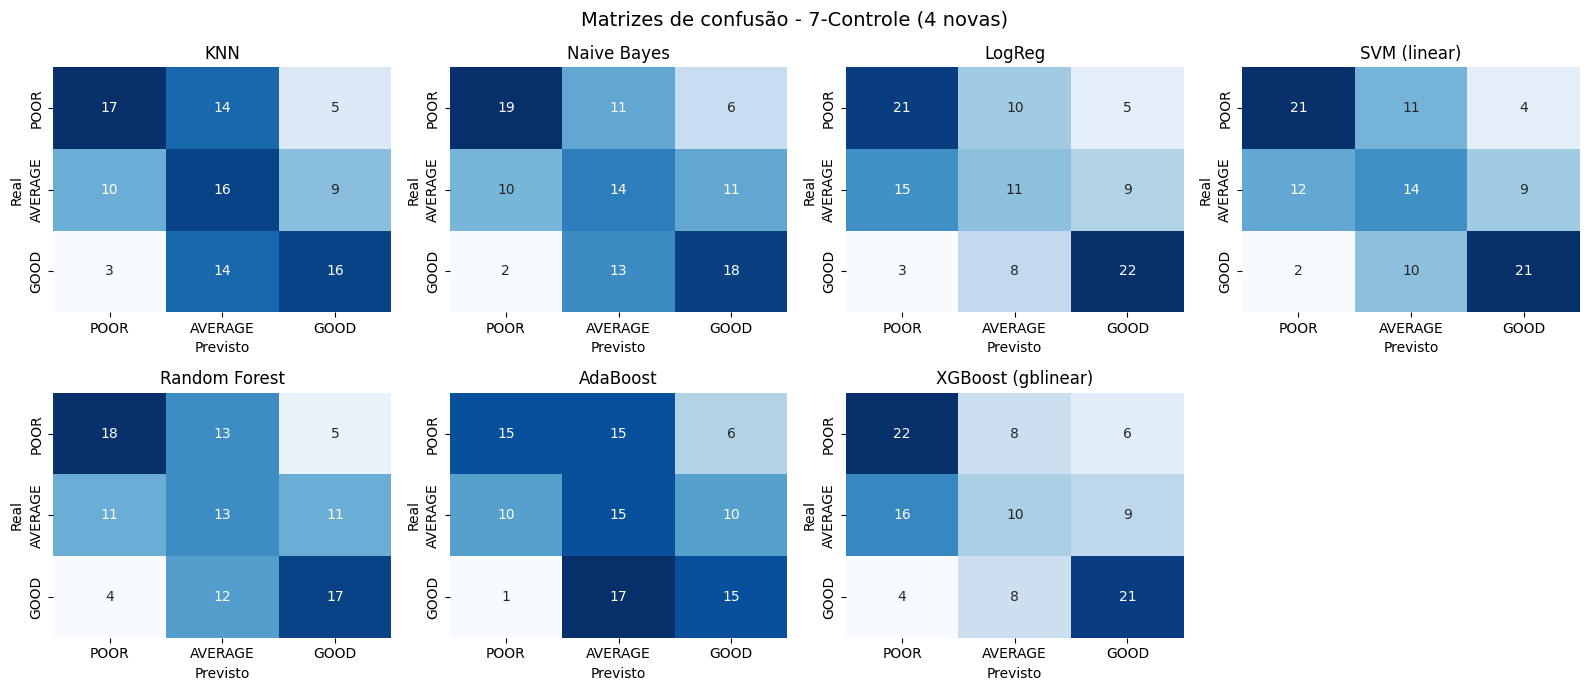


RANKING DOS MODELOS POR F1-MACRO CV:


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
XGBoost,0.5096,0.4973,0.5111,0.5002,0.5925
LogReg,0.5192,0.5096,0.5214,0.5138,0.5905
SVM,0.5385,0.5392,0.5399,0.5395,0.5853
Random Forest,0.4615,0.4676,0.4622,0.4644,0.5847
AdaBoost,0.4327,0.4600,0.4333,0.4395,0.5844
KNN,0.4712,0.4879,0.4714,0.4761,0.5720
Naive Bayes,0.4904,0.4985,0.4911,0.4934,0.5454



MELHOR MODELO POR VALIDAÇÃO CRUZADA:
XGBoost
F1-macro CV: 0.5925


,Acc,Prec,Rec,F1,CV
Modelo,,,,,
KNN,0.4712,0.4879,0.4714,0.4761,0.5720
Naive Bayes,0.4904,0.4985,0.4911,0.4934,0.5454
LogReg,0.5192,0.5096,0.5214,0.5138,0.5905
SVM,0.5385,0.5392,0.5399,0.5395,0.5853
Random Forest,0.4615,0.4676,0.4622,0.4644,0.5847
AdaBoost,0.4327,0.4600,0.4333,0.4395,0.5844
XGBoost,0.5096,0.4973,0.5111,0.5002,0.5925


In [ ]:
mostrar_cenario("7-Controle (4 novas)")

**Resultado:** KNN 0,452 · NB 0,490 · RF 0,490. Foi mal como devia — valida a confiabilidade do restante.

## 9. Tabela comparativa (divisão única 75/25)
**O que faz:** junta acurácia/precisão/F1 de todos os cenários + gráfico de barras.

=== MÉTRICAS NO HOLDOUT DE 25% ===

Acurácia


,KNN,Naive Bayes,LogReg,SVM,Random Forest,AdaBoost,XGBoost
Cenario,,,,,,,
1-Original +grupo,0.6442,0.5962,0.9423,0.9423,0.7692,0.8269,0.8750
2-PCA signif SEM grupo,0.6923,0.6058,0.8365,0.8462,0.7596,0.7500,0.8077
3-PCA signif COM grupo,0.6731,0.5096,0.8462,0.8462,0.7596,0.7019,0.8269
4-Cluster SEM grupo,0.7308,0.6346,0.9615,0.9615,0.7404,0.8462,0.8846
5-Cluster COM grupo,0.7212,0.5096,0.9615,0.9615,0.7788,0.8077,0.8750
6-Minimo SHAP +grupo,0.8462,0.5385,0.8846,0.8750,0.7788,0.7500,0.8654
7-Controle (4 novas),0.4712,0.4904,0.5192,0.5385,0.4615,0.4327,0.5096



Precisão (macro)


,KNN,Naive Bayes,LogReg,SVM,Random Forest,AdaBoost,XGBoost
Cenario,,,,,,,
1-Original +grupo,0.6982,0.6137,0.9468,0.9468,0.7916,0.8770,0.8826
2-PCA signif SEM grupo,0.7510,0.6674,0.8464,0.8578,0.7822,0.7912,0.8146
3-PCA signif COM grupo,0.7095,0.4816,0.8575,0.8533,0.7774,0.7320,0.8355
4-Cluster SEM grupo,0.7712,0.6908,0.9658,0.9658,0.7481,0.8696,0.8949
5-Cluster COM grupo,0.7397,0.4855,0.9658,0.9658,0.7991,0.8594,0.8880
6-Minimo SHAP +grupo,0.8725,0.4287,0.8952,0.8944,0.7960,0.7762,0.8739
7-Controle (4 novas),0.4879,0.4985,0.5096,0.5392,0.4676,0.4600,0.4973



Recall (macro)


,KNN,Naive Bayes,LogReg,SVM,Random Forest,AdaBoost,XGBoost
Cenario,,,,,,,
1-Original +grupo,0.6424,0.6034,0.9425,0.9425,0.7698,0.8263,0.8744
2-PCA signif SEM grupo,0.6918,0.6048,0.8376,0.8472,0.7597,0.7509,0.8091
3-PCA signif COM grupo,0.6724,0.5179,0.8463,0.8469,0.7597,0.7011,0.8281
4-Cluster SEM grupo,0.7288,0.6323,0.9621,0.9613,0.7401,0.8460,0.8847
5-Cluster COM grupo,0.7204,0.5182,0.9621,0.9621,0.7782,0.8067,0.8746
6-Minimo SHAP +grupo,0.8477,0.5463,0.8856,0.8757,0.7790,0.7513,0.8674
7-Controle (4 novas),0.4714,0.4911,0.5214,0.5399,0.4622,0.4333,0.5111


... (2 outputs left out)


Score de CV usado na seleção dos hiperparâmetros (otimista, pois serviu para escolher)


,KNN,Naive Bayes,LogReg,SVM,Random Forest,AdaBoost,XGBoost
Cenario,,,,,,,
1-Original +grupo,0.7268,0.5752,0.9425,0.9522,0.8185,0.8199,0.8789
2-PCA signif SEM grupo,0.7269,0.6568,0.8251,0.8237,0.7786,0.7789,0.8157
3-PCA signif COM grupo,0.7099,0.4992,0.8405,0.8401,0.7988,0.7843,0.8028
4-Cluster SEM grupo,0.7919,0.6532,0.9745,0.9683,0.8183,0.8298,0.9141
5-Cluster COM grupo,0.7625,0.5200,0.9654,0.9684,0.8097,0.8291,0.9082
6-Minimo SHAP +grupo,0.8025,0.4771,0.8348,0.8453,0.8027,0.8134,0.8257
7-Controle (4 novas),0.5720,0.5454,0.5905,0.5853,0.5847,0.5844,0.5925



Kernel do SVM e booster do XGBoost selecionados em cada cenário


,Cenario,SVM_Kernel,XGBoost_Booster
0,1-Original +grupo,linear,gblinear
1,2-PCA signif SEM grupo,rbf,gblinear
2,3-PCA signif COM grupo,linear,gblinear
3,4-Cluster SEM grupo,linear,gblinear
4,5-Cluster COM grupo,linear,gblinear
5,6-Minimo SHAP +grupo,rbf,gblinear
6,7-Controle (4 novas),linear,gblinear


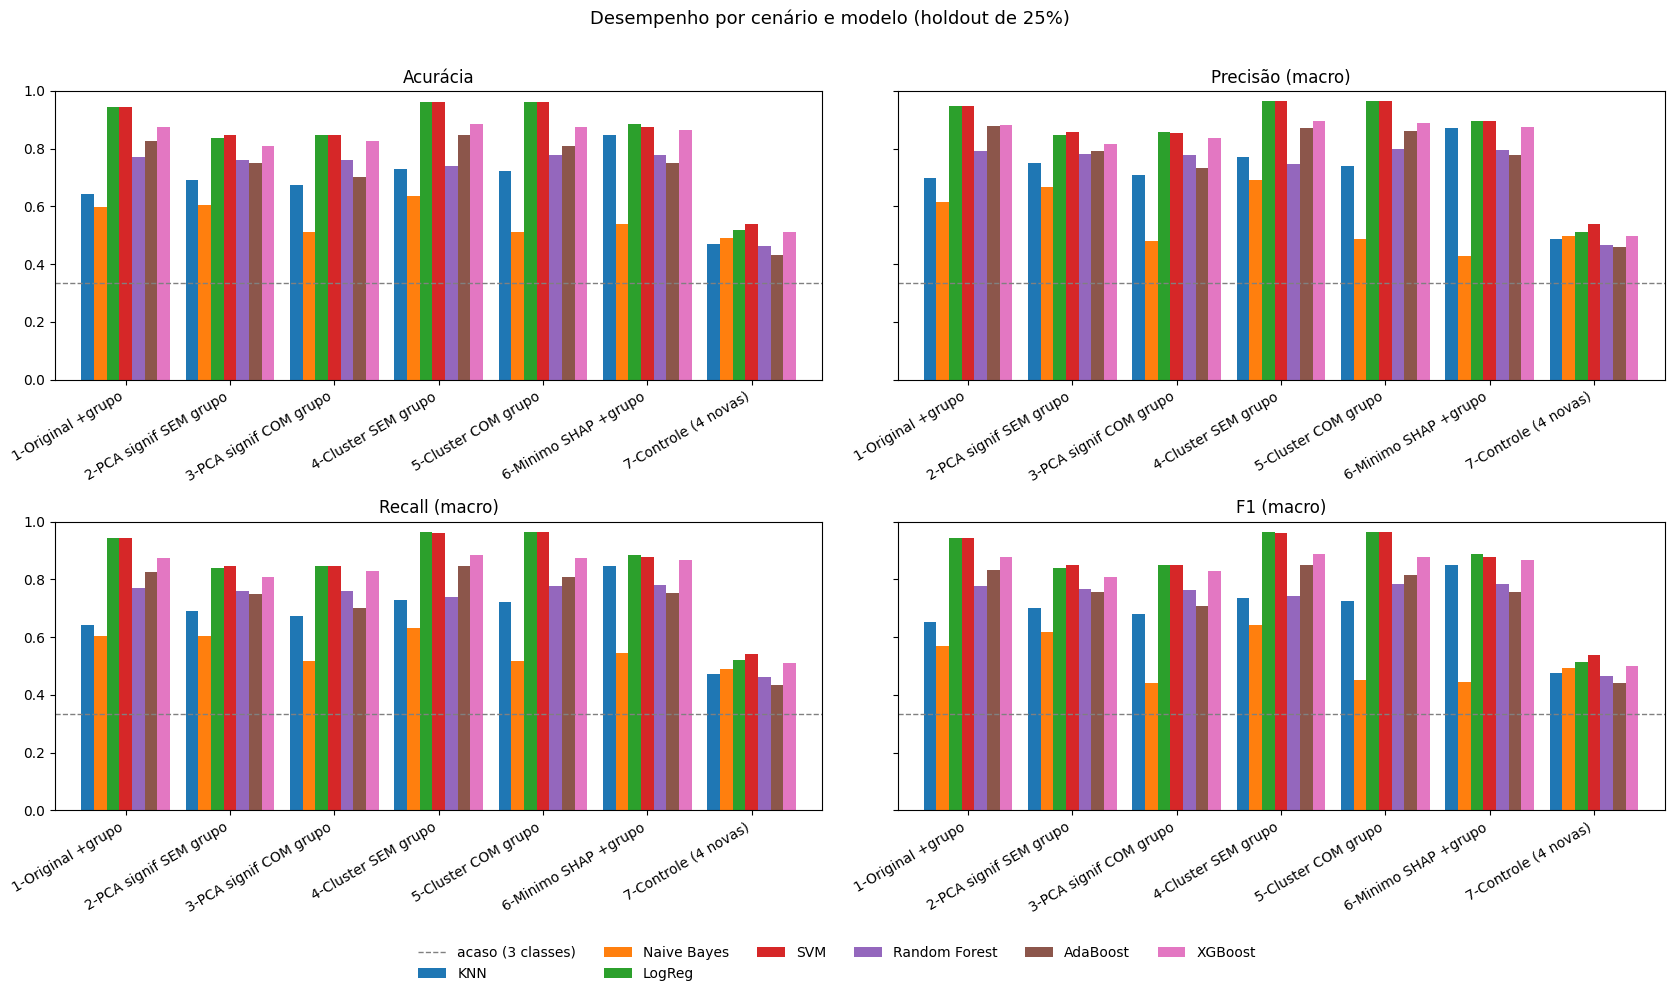

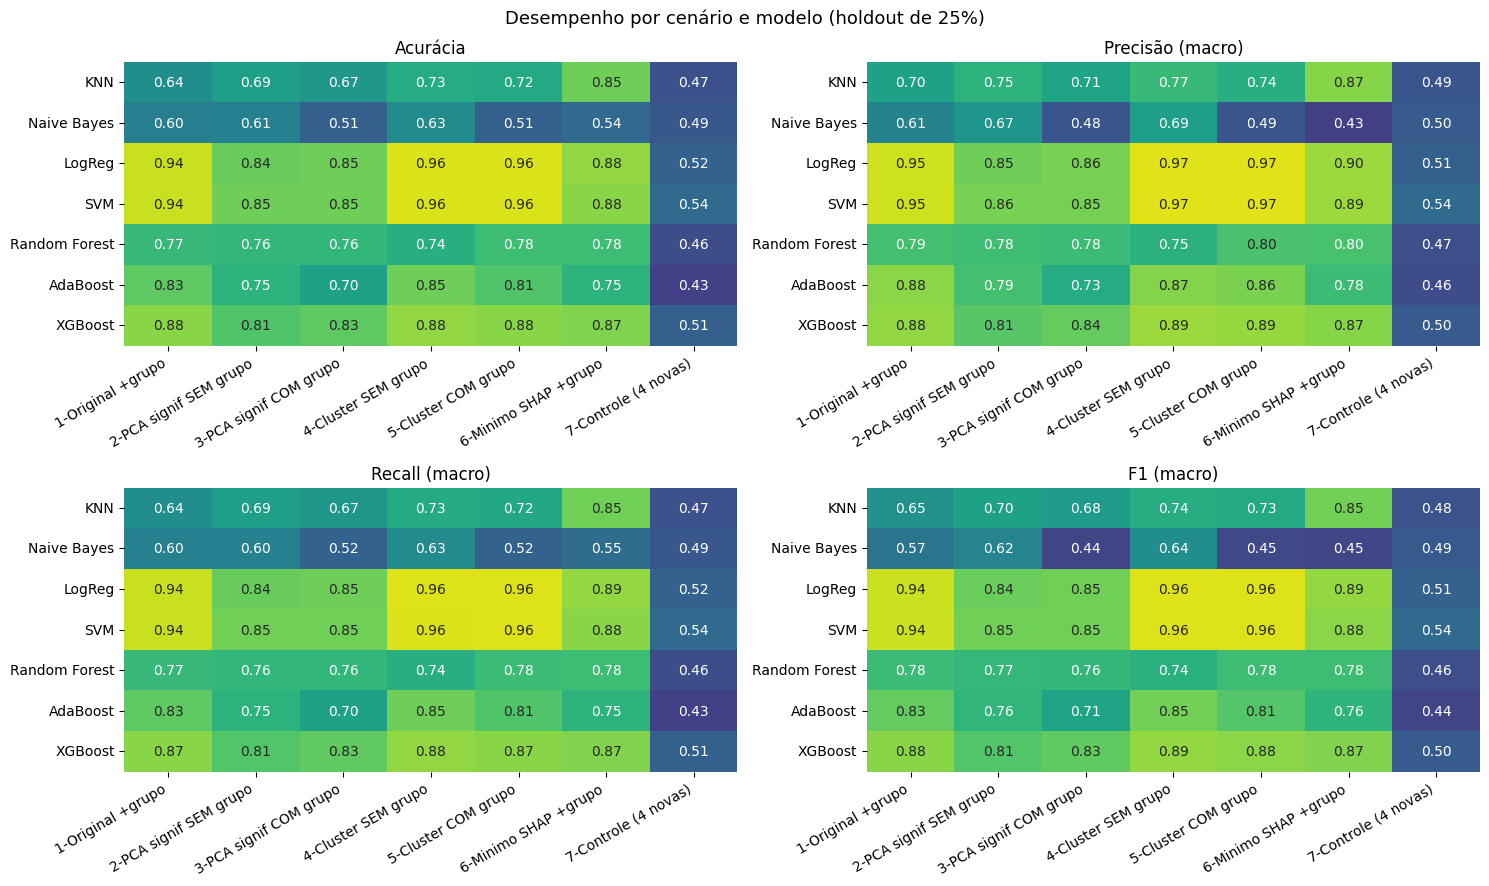


=== SVM: ACURÁCIA NO HOLDOUT POR KERNEL ===


KeyError: 'Acc'

In [ ]:
modelos = list(parametros.keys())


# =====================================================
# FUNÇÕES DE TABELA E GRÁFICO (reaproveitadas na validação cruzada)
# =====================================================
def sub(tabela, sigla, modelos):
    """Tabela Cenario x modelo para uma métrica (Acc, Prec, Rec, F1 ou CV)."""
    d = tabela.set_index("Cenario")[[f"{m}_{sigla}" for m in modelos]].copy()
    d.columns = modelos
    return d


def plotar_metricas(tabela, modelos, titulo="Desempenho por cenário e modelo (holdout de 25%)",
                    arquivo="metricas_barras.png"):
    """Quatro painéis de barras, um por métrica."""
    fig, axes = plt.subplots(2, 2, figsize=(17, 10), sharey=True)
    handles = labels = None
    for ax, (sigla, (nome_met, _)) in zip(axes.ravel(), METRICAS.items()):
        sub(tabela, sigla, modelos).plot(kind="bar", ax=ax, width=0.85)
        ax.axhline(1/3, ls="--", c="gray", lw=1, label="acaso (3 classes)")
        if handles is None:
            handles, labels = ax.get_legend_handles_labels()
        leg = ax.get_legend()
        if leg is not None:
            leg.remove()
        ax.set_title(nome_met)
        ax.set_xlabel("")
        ax.set_ylim(0, 1)
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    fig.legend(handles, labels, loc="lower center", ncol=min(len(labels), 6), frameon=False)
    fig.suptitle(titulo, fontsize=13)
    fig.tight_layout(rect=[0, 0.06, 1, 0.97])
    fig.savefig(arquivo, dpi=300, bbox_inches="tight")
    plt.show()


def plotar_heatmaps(tabela, modelos, titulo="", arquivo="metricas_heatmap.png"):
    """Quatro mapas de calor (modelo x cenário)."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for ax, (sigla, (nome_met, _)) in zip(axes.ravel(), METRICAS.items()):
        sns.heatmap(sub(tabela, sigla, modelos).T, annot=True, fmt=".2f", cmap="viridis",
                    vmin=0.3, vmax=1.0, cbar=False, ax=ax)
        ax.set_title(nome_met)
        ax.set_xlabel("")
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    if titulo:
        fig.suptitle(titulo, fontsize=13)
    fig.tight_layout()
    fig.savefig(arquivo, dpi=300, bbox_inches="tight")
    plt.show()


# =====================================================
# CONSOLIDAÇÃO (usa só os cenários já rodados; não faz nenhuma busca)
# =====================================================
def consolidar():
    """Monta as tabelas e os gráficos finais a partir dos cenários já rodados."""
    global tabela
    faltam = [n for n in cenarios if n not in _cache]
    if faltam:
        print("Ainda não rodados (rode a célula de cada teste): " + ", ".join(faltam))
        return
    tabela = pd.DataFrame([_cache[n] for n in cenarios])

    print("=== MÉTRICAS NO HOLDOUT DE 25% ===")
    for sigla, (nome_met, _) in METRICAS.items():
        print(f"\n{nome_met}")
        display(sub(tabela, sigla, modelos))

    print("\nScore de CV usado na seleção dos hiperparâmetros (otimista, pois serviu para escolher)")
    display(sub(tabela, "CV", modelos))

    print("\nKernel do SVM e booster do XGBoost selecionados em cada cenário")
    display(tabela[["Cenario", "SVM_Kernel", "XGBoost_Booster"]])

    plotar_metricas(tabela, modelos)
    plotar_heatmaps(tabela, modelos, titulo="Desempenho por cenário e modelo (holdout de 25%)")

    # Comparação das variantes (kernels do SVM e boosters do XGBoost), extraídas da mesma busca
    for nome_modelo, campo in VARIANTES.items():
        tv = tabela_variantes(nome_modelo)
        for sigla, (nome_met, _) in METRICAS.items():
            print(f"\n=== {nome_modelo}: {nome_met.upper()} NO HOLDOUT POR {campo.upper()} ===")
            display(tv.pivot(index="Cenario", columns="Variante", values=sigla).reindex(list(cenarios)))
        print(f"\n=== {nome_modelo}: SCORE DE CV POR {campo.upper()} (usado na escolha) ===")
        display(tv.pivot(index="Cenario", columns="Variante", values="CV_score").reindex(list(cenarios)))

    # Salvar resultados
    cols_csv = ["Cenario", "n_vars"] + [f"{m}_{s}" for m in modelos for s in list(METRICAS) + ["CV"]]
    tabela[cols_csv].to_csv("resultados_metricas.csv", index=False)
    pd.concat([tabela_variantes(m).assign(Modelo=m) for m in VARIANTES]).drop(columns="Params").to_csv(
        "resultados_variantes.csv", index=False)


consolidar()

**Leitura:** Random Forest é o mais **estável**; Naive Bayes é o mais fraco; KNN **oscila**. Estes números vêm de
**uma** divisão treino/teste — por isso, a seguir, confirmamos com validação cruzada.

## 9.1 Validação cruzada (5-fold) — o número que dá segurança

**O que faz:** em vez de uma única divisão, treina/testa **5 vezes** em partições diferentes e reporta a **média ± desvio**.
Se o desvio for grande, o resultado é instável; se dois cenários diferem menos que o desvio, a diferença **não é significativa**.

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Mesma definição de métrica do restante do notebook (média macro, zero_division=0)
scoring_cv = {
    "Acc":  "accuracy",
    "Prec": make_scorer(precision_score, average="macro", zero_division=0),
    "Rec":  make_scorer(recall_score,    average="macro", zero_division=0),
    "F1":   make_scorer(f1_score,        average="macro", zero_division=0),
}

medias, desvios = [], []
for nome, (nums, g) in cenarios.items():
    cols = nums + (["Supplier_Group"] if g else [])
    pre = montar_pre(nums, g)
    rm = {"Cenario": nome, "n_vars": len(cols)}
    rd = dict(rm)
    for mn, model in models.items():
        r = cross_validate(
            Pipeline([("pre", pre), ("model", model)]),
            df[cols], Y, cv=cv, scoring=scoring_cv, n_jobs=-1
        )
        for sig in scoring_cv:
            rm[f"{mn}_{sig}"] = r[f"test_{sig}"].mean()
            rd[f"{mn}_{sig}"] = r[f"test_{sig}"].std()
    medias.append(rm)
    desvios.append(rd)

cv_medias = pd.DataFrame(medias)     # médias numéricas (mesmo formato de nomes usado nos gráficos)
cv_dp = pd.DataFrame(desvios)        # desvios-padrão
modelos_cv = list(models)


def tabela_cv(sig):
    """Tabela 'média ± desvio' para uma métrica."""
    tab = cv_medias[["Cenario", "n_vars"]].copy()
    for mn in modelos_cv:
        tab[mn] = [f"{a:.3f} ± {b:.3f}"
                   for a, b in zip(cv_medias[f"{mn}_{sig}"], cv_dp[f"{mn}_{sig}"])]
    return tab


for sig in METRICAS:
    print(f"\n=== {METRICAS[sig][0].upper()} — VALIDAÇÃO CRUZADA (média ± desvio, 5-fold) ===")
    display(tabela_cv(sig))

cv_tab = tabela_cv("Acc")            # mantém o nome usado na versão anterior

plotar_metricas(cv_medias, modelos_cv,
                titulo="Validação cruzada 5-fold (hiperparâmetros padrão)",
                arquivo="metricas_barras_cv.png")
plotar_heatmaps(cv_medias, modelos_cv,
                titulo="Validação cruzada 5-fold (hiperparâmetros padrão)",
                arquivo="metricas_heatmap_cv.png")

cv_medias.to_csv("resultados_cv_medias.csv", index=False)
cv_dp.to_csv("resultados_cv_desvios.csv", index=False)

**Leitura (importante para a defesa):**
- O **Random Forest** confirma ~**0,79–0,81** de forma estável (desvio baixo).
- O **pico do KNN** (0,837 na divisão única) cai para ~0,80 na validação cruzada — era **otimismo da partição**.
- As diferenças entre "com" e "sem" grupo (Testes 2↔3, 4↔5) ficam **dentro do desvio (±0,05)** → o efeito do grupo
  **não é estatisticamente forte**. Mensagem honesta: o grupo **contribui, mas não é determinante**.

## 9.2 Trade-off: nº de variáveis × acurácia
**O que faz:** cruza o tamanho do modelo (nº de variáveis) com a acurácia (Random Forest, divisão única). Mostra
visualmente que dá para **usar menos variáveis sem perder desempenho**.

In [ ]:
from matplotlib.lines import Line2D


def plotar_tradeoff(tabela, modelos, titulo, arquivo):
    """Nº de variáveis x métrica, um painel por métrica. Cor = modelo; o número no marcador = cenário."""
    cores = sns.color_palette("tab10", n_colors=len(modelos))
    passo = 0.8 / len(modelos)                                # faixa total de 0,8 no eixo x, qualquer que seja o nº de modelos
    fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)
    for ax, (sigla, (nome_met, _)) in zip(axes.ravel(), METRICAS.items()):
        for i, mn in enumerate(modelos):
            dx = (i - (len(modelos) - 1) / 2) * passo         # desloca cada modelo para não sobrepor
            for _, r in tabela.iterrows():
                num = r["Cenario"].split("-")[0]
                ax.scatter(r["n_vars"] + dx, r[f"{mn}_{sigla}"], s=110,
                           color=cores[i], marker=f"${num}$", linewidths=0.3)
        ax.axhline(1/3, ls="--", c="gray", lw=1)
        ax.set_title(nome_met)
        ax.set_xlabel("Nº de variáveis no modelo")
        ax.set_ylabel(nome_met)
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.3)
    handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=cores[i],
                      markersize=9, label=mn) for i, mn in enumerate(modelos)]
    handles.append(Line2D([0], [0], ls="--", color="gray", label="acaso (3 classes)"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 6), frameon=False)
    fig.suptitle(f"{titulo}\n(o número em cada ponto indica o cenário)", fontsize=13)
    fig.tight_layout(rect=[0, 0.07, 1, 0.94])
    fig.savefig(arquivo, dpi=300, bbox_inches="tight")
    plt.show()


def plotar_delta(tabela, modelos, titulo, arquivo, base="1-Original +grupo"):
    """Variação de cada métrica em relação ao cenário base, por modelo e cenário."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for ax, (sigla, (nome_met, _)) in zip(axes.ravel(), METRICAS.items()):
        d = sub(tabela, sigla, modelos)
        delta = d.sub(d.loc[base], axis=1)                    # cada cenário menos o cenário base
        sns.heatmap(delta.T, annot=True, fmt="+.2f", cmap="RdBu", center=0,
                    vmin=-0.5, vmax=0.5, cbar=False, ax=ax)
        ax.set_title(f"{nome_met}: variação frente ao cenário {base.split('-')[0]}")
        ax.set_xlabel("")
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
    fig.suptitle(titulo, fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(arquivo, dpi=300, bbox_inches="tight")
    plt.show()


# Holdout de 25% (hiperparâmetros otimizados): todos os modelos, todas as métricas
plotar_tradeoff(tabela, modelos,
                "Nº de variáveis × desempenho (holdout de 25%)", "tradeoff_holdout.png")
plotar_delta(tabela, modelos,
             "Perda ou ganho em relação ao modelo completo (holdout de 25%)", "delta_holdout.png")

# Validação cruzada 5-fold (hiperparâmetros padrão): todos os modelos, todas as métricas
plotar_tradeoff(cv_medias, modelos_cv,
                "Nº de variáveis × desempenho (validação cruzada 5-fold)", "tradeoff_cv.png")
plotar_delta(cv_medias, modelos_cv,
             "Perda ou ganho em relação ao modelo completo (validação cruzada 5-fold)", "delta_cv.png")

**Leitura:** exceto o controle (Teste 7), os cenários se agrupam em torno de ~0,76–0,80 **independentemente**
de terem 6 ou 17 variáveis. Ou seja, a complexidade extra quase não traz ganho — argumento a favor da simplicidade.

## 9.3 Desempenho por classe (onde o modelo erra mais)
**O que faz:** mostra o relatório detalhado (precisão/recall por classe) do melhor cenário — revela **qual faixa**
(POOR, AVERAGE ou GOOD) é mais difícil de acertar.

In [ ]:
from sklearn.metrics import classification_report, precision_recall_fscore_support

# Cenário analisado: o de maior acurácia do Random Forest (critério original).
# Para olhar outro cenário, escreva o nome, por exemplo: melhor = "5-Cluster COM grupo"
melhor = tabela.sort_values("Random Forest_Acc", ascending=False).iloc[0]["Cenario"]
print(f"Cenário analisado: {melhor}\n")

# Desempenho por classe de todos os modelos
linhas = []
for mn in modelos:
    d = _store[(melhor, mn)]
    p, r, f, s = precision_recall_fscore_support(
        d["y_test"], d["pred"], labels=range(len(y_enc.classes_)), zero_division=0
    )
    for i, classe in enumerate(y_enc.classes_):
        linhas.append({"Modelo": mn, "Classe": classe,
                       "Precisão": round(p[i], 3), "Recall": round(r[i], 3),
                       "F1": round(f[i], 3), "Suporte": int(s[i])})
por_classe = pd.DataFrame(linhas)

for met in ("Precisão", "Recall", "F1"):
    print(f"=== {met.upper()} POR CLASSE ===")
    display(por_classe.pivot(index="Modelo", columns="Classe", values=met)[classes].reindex(modelos))

suporte = por_classe[por_classe["Modelo"] == modelos[0]].set_index("Classe")["Suporte"].reindex(classes)
print("Nº de fornecedores por classe no teste:", suporte.to_dict())

# Relatório completo dos dois modelos centrais na discussão
for mn in ("Random Forest", "LogReg"):
    d = _store[(melhor, mn)]
    print(f"\n--- {mn} ---")
    print(classification_report(d["y_test"], d["pred"], target_names=y_enc.classes_, zero_division=0))

**Leitura:** normalmente a classe **AVERAGE** é a mais difícil (fica "no meio" entre POOR e GOOD, então o
modelo confunde mais). Precisão alta em GOOD/POOR significa que, quando o modelo aponta essas faixas, costuma acertar —
útil para o negócio priorizar/descartar fornecedores com confiança.

## 10. Efeito do grupo (a pergunta metodológica central)
**O que faz:** compara diretamente os pares sem × com grupo, na validação cruzada (mais confiável).

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

scoring_grupo = {
    "Acc":  "accuracy",
    "Prec": make_scorer(precision_score, average="macro", zero_division=0),
    "Rec":  make_scorer(recall_score,    average="macro", zero_division=0),
    "F1":   make_scorer(f1_score,        average="macro", zero_division=0),
}

pares = {
    "PCA":     ("2-PCA signif SEM grupo", "3-PCA signif COM grupo"),
    "Cluster": ("4-Cluster SEM grupo",    "5-Cluster COM grupo"),
}


def scores_folds(nome):
    """Score de cada fold, por modelo e métrica, para um cenário."""
    nums, g = cenarios[nome]
    cols = nums + (["Supplier_Group"] if g else [])
    pre = montar_pre(nums, g)
    saida = {}
    for mn, model in models.items():
        r = cross_validate(Pipeline([("pre", pre), ("model", model)]),
                           df[cols], Y, cv=cv, scoring=scoring_grupo, n_jobs=-1)
        saida[mn] = {sig: r[f"test_{sig}"] for sig in scoring_grupo}
    return saida


# Mesmos folds nos dois cenários do par (cv tem semente fixa), então a diferença é pareada
linhas = []
for par, (sem, com) in pares.items():
    a, b = scores_folds(sem), scores_folds(com)
    for mn in models:
        for sig in scoring_grupo:
            d = b[mn][sig] - a[mn][sig]                      # com grupo menos sem grupo, fold a fold
            linhas.append({"Par": par, "Modelo": mn, "Metrica": sig,
                           "Sem": a[mn][sig].mean(), "Com": b[mn][sig].mean(),
                           "Delta": d.mean(), "dp_Delta": d.std(),
                           "folds_melhor": int((d > 0).sum())})
efeito = pd.DataFrame(linhas)

# Tabelas: variação média ± desvio da diferença (folds em que o grupo melhorou)
for sig in scoring_grupo:
    print(f"\n=== EFEITO DO GRUPO: {METRICAS[sig][0].upper()} (com grupo menos sem grupo) ===")
    tab = pd.DataFrame(index=list(models))
    for par in pares:
        e = efeito[(efeito["Par"] == par) & (efeito["Metrica"] == sig)].set_index("Modelo").reindex(list(models))
        tab[par] = [f"{r.Delta:+.3f} ± {r.dp_Delta:.3f} ({r.folds_melhor}/5)" for r in e.itertuples()]
    display(tab)

# Mapa de calor da variação média
fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for ax, (sig, (nome_met, _)) in zip(axes.ravel(), METRICAS.items()):
    m = efeito[efeito["Metrica"] == sig].pivot(index="Modelo", columns="Par", values="Delta")
    m = m.reindex(index=list(models), columns=list(pares))
    sns.heatmap(m, annot=True, fmt="+.3f", cmap="RdBu", center=0, vmin=-0.1, vmax=0.1, cbar=False, ax=ax)
    ax.set_title(nome_met); ax.set_ylabel(""); ax.set_xlabel("")
fig.suptitle("Efeito do grupo: variação média (validação cruzada 5-fold)", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("efeito_grupo_cv.png", dpi=300, bbox_inches="tight")
plt.show()

efeito.to_csv("resultados_efeito_grupo.csv", index=False)

**Significa:** as diferenças entre com/sem grupo são **menores que o desvio** — ou seja, estão dentro da
margem de erro. Conclusão equilibrada e defensável: a etapa PCA + K-Means **agrega informação (o grupo aparece no
SHAP), mas o ganho de acurácia não é determinante**.

## 11. SHAP — explicar o Random Forest
**O que faz:** mostra o **ranking de importância** das variáveis na previsão (e se o grupo aparece entre as mais influentes).

In [ ]:
# =====================================================
# 11.0 ESCOLHA DO MELHOR (cenário x modelo) POR MÉTRICA COMPOSTA
# =====================================================
# Pesos de cada métrica no score (são normalizados para somar 1).
# Acc, Prec, Rec, F1 = holdout de 25%; CV = score de CV usado na seleção dos hiperparâmetros.
PESOS = {"F1": 0.35, "Acc": 0.25, "Prec": 0.10, "Rec": 0.10, "CV": 0.20}
CENARIOS_EXCLUIDOS = ["7-Controle (4 novas)"]     # o controle é teste de sanidade, não entra na escolha
MODELOS_EXCLUIDOS = []                            # ex.: ["Naive Bayes", "KNN"]
PENALIDADE_POR_VARIAVEL = 0.0                     # ex.: 0.002 favorece modelos com menos variáveis
ESCOLHA_MANUAL = None                             # ex.: ("1-Original +grupo", "LogReg") ignora o ranking
N_RANKING = 10                                    # linhas mostradas no ranking

if "tabela" not in globals():
    raise RuntimeError("Rode antes a seção 9 (tabela comparativa).")

soma = sum(PESOS.values())
pesos = {k: v / soma for k, v in PESOS.items()}


def montar_ranking():
    linhas = []
    for _, r in tabela.iterrows():
        if r["Cenario"] in CENARIOS_EXCLUIDOS:
            continue
        for mn in modelos:
            if mn in MODELOS_EXCLUIDOS:
                continue
            score = sum(pesos[s] * r[f"{mn}_{s}"] for s in pesos) - PENALIDADE_POR_VARIAVEL * r["n_vars"]
            linhas.append({"Cenario": r["Cenario"], "Modelo": mn, "n_vars": int(r["n_vars"]),
                           "Score": score, **{s: r[f"{mn}_{s}"] for s in pesos}})
    return pd.DataFrame(linhas).sort_values("Score", ascending=False).reset_index(drop=True)


ranking = montar_ranking()

# ---------- escolha ----------
if ESCOLHA_MANUAL is not None:
    alvo, modelo_alvo = ESCOLHA_MANUAL
else:
    alvo, modelo_alvo = ranking.loc[0, "Cenario"], ranking.loc[0, "Modelo"]

lin = tabela.set_index("Cenario").loc[alvo]
score_alvo = sum(pesos[s] * lin[f"{modelo_alvo}_{s}"] for s in pesos) - PENALIDADE_POR_VARIAVEL * lin["n_vars"]
pos = ranking[(ranking["Cenario"] == alvo) & (ranking["Modelo"] == modelo_alvo)].index

# ---------- destaque do melhor ----------
print("=" * 72)
print(f"MELHOR: {modelo_alvo}   |   cenário: {alvo}" + ("   (escolha manual)" if ESCOLHA_MANUAL is not None else ""))
print("=" * 72)
print("Pesos usados:", {k: round(v, 3) for k, v in pesos.items()})

card = pd.DataFrame({
    "Nº de variáveis": [int(lin["n_vars"])],
    "Score composto":  [score_alvo],
    "F1 (macro)":      [lin[f"{modelo_alvo}_F1"]],
    "Acurácia":        [lin[f"{modelo_alvo}_Acc"]],
    "Precisão (macro)": [lin[f"{modelo_alvo}_Prec"]],
    "Recall (macro)":  [lin[f"{modelo_alvo}_Rec"]],
    "Score de CV":     [lin[f"{modelo_alvo}_CV"]],
}).round(3).T
card.columns = ["Valor"]
display(card)

if modelo_alvo == "SVM":
    print("Kernel selecionado:", lin["SVM_Kernel"])
if modelo_alvo == "XGBoost":
    print("Booster selecionado:", lin["XGBoost_Booster"])
print("Hiperparâmetros:", {k.replace("model__", ""): v for k, v in lin[f"{modelo_alvo}_Grid_Params"].items()})
if len(pos):
    print(f"Posição no ranking: {int(pos[0]) + 1}º de {len(ranking)}")

if ESCOLHA_MANUAL is None and len(ranking) > 1:
    dif = ranking.loc[0, "Score"] - ranking.loc[1, "Score"]
    print(f"Vantagem sobre o 2º ({ranking.loc[1, 'Modelo']} | {ranking.loc[1, 'Cenario']}): {dif:.3f}")
    if dif < 0.01:
        print("ATENÇÃO: diferença menor que 0,01, dentro do ruído do holdout. "
              "Confira o ranking e, se preferir, use ESCOLHA_MANUAL.")

# ---------- ranking ----------
exib = ranking.copy()
exib.index = np.arange(1, len(exib) + 1)
exib.index.name = "Posição"


def _destaque(linha):
    melhor = (linha["Cenario"] == alvo) and (linha["Modelo"] == modelo_alvo)
    return ["background-color: #ffe08a; font-weight: bold" if melhor else "" for _ in linha]


print(f"\nTop {N_RANKING} (cenário x modelo); o escolhido aparece em destaque, se estiver entre eles:")
display(exib.head(N_RANKING).style.format({c: "{:.3f}" for c in ["Score"] + list(pesos)}).apply(_destaque, axis=1))

# gráfico de barras do ranking (o escolhido em vermelho)
top = ranking.head(N_RANKING)
rotulos = (top["Modelo"] + " | " + top["Cenario"]).iloc[::-1]
cores = ["#d62728" if (m == modelo_alvo and c == alvo) else "#8fa8c8"
         for m, c in zip(top["Modelo"], top["Cenario"])][::-1]
valores_top = top["Score"].iloc[::-1]
plt.figure(figsize=(10, 0.45 * len(top) + 1.5))
plt.barh(rotulos, valores_top, color=cores)
for i, v in enumerate(valores_top):
    plt.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
plt.xlim(max(0, top["Score"].min() - 0.05), min(1.0, top["Score"].max() + 0.03))
plt.xlabel("Score composto (atenção: o eixo não começa em zero)")
plt.title("Ranking por métrica composta")
plt.tight_layout()
plt.savefig("ranking_melhor.png", dpi=300, bbox_inches="tight")
plt.show()

# melhor cenário de cada modelo e melhor modelo de cada cenário
print("\nMelhor cenário de cada modelo:")
display(ranking.loc[ranking.groupby("Modelo")["Score"].idxmax()]
        .sort_values("Score", ascending=False).reset_index(drop=True).round(3))

print("\nMelhor modelo de cada cenário:")
display(ranking.loc[ranking.groupby("Cenario")["Score"].idxmax()]
        .sort_values("Score", ascending=False).reset_index(drop=True).round(3))

# mapa de calor do score (modelo x cenário)
piv = ranking.pivot(index="Modelo", columns="Cenario", values="Score")
piv = piv[[c for c in cenarios if c in piv.columns]].reindex(modelos)
plt.figure(figsize=(11, 0.6 * len(piv) + 2))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", cbar=False)
plt.title("Score composto por modelo e cenário")
plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("ranking_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"\nSeguindo para o SHAP: {modelo_alvo} no cenário '{alvo}'.")

**Significa:** as variáveis no topo pesam mais na previsão — tipicamente **risco financeiro, entrega no prazo,
prêmios, preço e avaliação**, coerente com supply chain. Quando presente, o `Supplier_Group` aparece entre as
relevantes, reforçando que a segmentação carrega informação útil.

## 12. Conclusões

1. **~0,80 de acurácia** é atingível (Random Forest), confirmado por validação cruzada.
2. **Modelos enxutos (5–9 variáveis) mantêm o desempenho** do modelo completo → mais fáceis de explicar.
3. O **grupo contribui, mas o ganho está dentro da margem de erro** → resposta equilibrada e honesta.
4. **Sanidade confirmada:** o cenário de controle vai mal, como esperado.

**Ressalvas e próximos passos:** o PCA explica só 59% da variância; PC3 é quase só `relationship_years`;
o pico do KNN é instável (RF é o número robusto). Próximos passos: **ajuste de hiperparâmetros**, **SHAP por classe**
e definir se o objetivo final é **classificação** (faixa) ou **ranking/recomendação** de fornecedores.

In [ ]:
# ============================================================
# 12. SISTEMA DE RECOMENDAÇÃO DE FORNECEDORES
#     Cenário 4-Cluster SEM grupo + SVM LINEAR
#
#     CÓDIGO CONSOLIDADO E AUTOSSUFICIENTE
# ============================================================

import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import loguniform, uniform

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    GridSearchCV
)

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# 12.1 CONFIGURAÇÕES
# ============================================================

SEED = 42

CENARIO_RECOMENDACAO = "4-Cluster SEM grupo"
MODELO_RECOMENDACAO = "SVM"
KERNEL_RECOMENDACAO = "linear"

SCORING = "f1_macro"

CV_INTERNO = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Mesma lógica da versão "rápida" utilizada no notebook.
# Se quiser a rodada final completa, mude para:
# MODO_RECOMENDACAO = "completo"

MODO_RECOMENDACAO = "completo"

N_ITER_SVM = (
    10
    if MODO_RECOMENDACAO == "rapido"
    else 120
)

TOP_N = 10

LIMIAR_ALTA = 70
LIMIAR_MEDIA = 50


print("=" * 80)
print("12. SISTEMA DE RECOMENDAÇÃO DE FORNECEDORES")
print("4-Cluster SEM grupo + SVM LINEAR")
print("=" * 80)


# ============================================================
# 12.2 DEFINIÇÕES DAS VARIÁVEIS ORIGINAIS
# ============================================================

preds12 = [
    "n_awards",
    "price_index_vs_market",
    "sustainability_score",
    "defect_rate_pct",
    "relationship_years",
    "monthly_capacity_units",
    "on_time_delivery_pct",
    "avg_rating",
    "financial_risk_prob_default",
    "co2_kg_per_unit",
    "n_events",
    "avg_lead_time_days"
]


extras4 = [
    "responsiveness_score",
    "innovation_score",
    "avg_offer_price_index",
    "avg_offer_lead_time"
]


feats16 = preds12 + extras4

target = "performance_band"

classes = [
    "POOR",
    "AVERAGE",
    "GOOD"
]


# ============================================================
# 12.3 CARREGAR A BASE CASO df NÃO EXISTA
# ============================================================

def carregar_base_recomendacao():

    # --------------------------------------------------------
    # 1. Se df já existe no notebook, reaproveita
    # --------------------------------------------------------

    if (
        "df" in globals()
        and isinstance(globals()["df"], pd.DataFrame)
        and target in globals()["df"].columns
    ):

        print("Base df encontrada na memória.")
        return globals()["df"].copy()


    # --------------------------------------------------------
    # 2. Procurar arquivo definido anteriormente em CAMINHO
    # --------------------------------------------------------

    candidatos = []

    if "CAMINHO" in globals():

        caminho_anterior = globals()["CAMINHO"]

        if (
            isinstance(caminho_anterior, str)
            and os.path.exists(caminho_anterior)
        ):

            candidatos.append(
                caminho_anterior
            )


    # --------------------------------------------------------
    # 3. Procurar automaticamente planilhas na pasta
    # --------------------------------------------------------

    candidatos.extend(
        glob.glob("*.xlsx")
    )

    candidatos.extend(
        glob.glob("*.xls")
    )


    # Remover duplicados
    candidatos = list(
        dict.fromkeys(candidatos)
    )


    # --------------------------------------------------------
    # 4. Se encontrou planilha, tenta abrir SUPPLIERS
    # --------------------------------------------------------

    for arquivo in candidatos:

        try:

            base = pd.read_excel(
                arquivo,
                sheet_name="SUPPLIERS"
            )

            if target in base.columns:

                print(
                    f"Base carregada automaticamente: "
                    f"{arquivo}"
                )

                return base

        except Exception:

            pass


    # --------------------------------------------------------
    # 5. Caso esteja no Google Colab, solicita upload
    # --------------------------------------------------------

    try:

        from google.colab import files

        print(
            "\nA base Excel não está na memória."
        )

        print(
            "Selecione agora a planilha original "
            "dos fornecedores."
        )

        uploaded = files.upload()

        arquivos_excel = [
            nome
            for nome in uploaded.keys()
            if nome.lower().endswith(
                (".xlsx", ".xls")
            )
        ]

        if not arquivos_excel:

            raise RuntimeError(
                "Nenhum arquivo Excel foi enviado."
            )

        arquivo = arquivos_excel[0]

        base = pd.read_excel(
            arquivo,
            sheet_name="SUPPLIERS"
        )

        print(
            f"Base carregada: {arquivo}"
        )

        return base


    except ImportError:

        raise FileNotFoundError(
            "Não encontrei a base Excel. "
            "Coloque o arquivo .xlsx na mesma pasta "
            "do notebook e execute novamente."
        )


# Carregar
df_original_rec = carregar_base_recomendacao()


# ============================================================
# 12.4 LIMPEZA IGUAL À UTILIZADA ANTERIORMENTE
# ============================================================

colunas_obrigatorias = (
    feats16
    +
    [target]
)

faltantes = [
    coluna
    for coluna in colunas_obrigatorias
    if coluna not in df_original_rec.columns
]

if faltantes:

    raise ValueError(
        "A planilha não contém todas as variáveis "
        "utilizadas no estudo.\n\n"
        f"Variáveis faltantes:\n{faltantes}"
    )


df = (
    df_original_rec[
        df_original_rec[target].isin(classes)
    ]
    .copy()
)


df = df.dropna(
    subset=feats16 + [target]
).copy()


print(
    "\nFornecedores após limpeza:",
    len(df)
)

print(
    "Distribuição do alvo:",
    df[target].value_counts().to_dict()
)


# ============================================================
# 12.5 RECONSTRUIR PCA + K-MEANS
#     APENAS PARA OBTER AS VARIÁVEIS DO CENÁRIO 4
# ============================================================
#
# IMPORTANTE:
#
# O Supplier_Group NÃO entra no SVM do cenário 4.
#
# O clustering é utilizado aqui somente para reconstruir
# exatamente o conjunto de variáveis "clust9" empregado
# anteriormente.
# ============================================================

scaler_cluster = StandardScaler()

X_cluster = scaler_cluster.fit_transform(
    df[preds12]
)


pca3_rec = PCA(
    n_components=3
)

X_pca_rec = pca3_rec.fit_transform(
    X_cluster
)


kmeans_rec = KMeans(
    n_clusters=3,
    random_state=80,
    n_init=10
)


df["Supplier_Group"] = (
    kmeans_rec.fit_predict(
        X_pca_rec
    )
)


# Dados padronizados das 12 variáveis
Z_rec = pd.DataFrame(
    StandardScaler().fit_transform(
        df[preds12]
    ),
    columns=preds12,
    index=df.index
)


Z_rec["g"] = (
    df["Supplier_Group"].values
)


perfil_rec = (
    Z_rec
    .groupby("g")[preds12]
    .mean()
)


# Mesma lógica anterior:
# top 4 variáveis em valor absoluto de cada cluster;
# depois união das variáveis.

clust9_rec = sorted({

    variavel

    for grupo in perfil_rec.index

    for variavel in (
        perfil_rec
        .loc[grupo]
        .abs()
        .sort_values(
            ascending=False
        )
        .head(4)
        .index
    )

})


variaveis_recomendacao = (
    clust9_rec
)


print(
    "\nVariáveis reconstruídas para "
    "'4-Cluster SEM grupo':"
)

for i, variavel in enumerate(
    variaveis_recomendacao,
    start=1
):

    print(
        f"{i:02d}. {variavel}"
    )


print(
    f"\nNúmero total de variáveis: "
    f"{len(variaveis_recomendacao)}"
)


# ============================================================
# 12.6 DEFINIR O ALVO
# ============================================================

y_enc = LabelEncoder().fit(
    df[target]
)


Y = y_enc.transform(
    df[target]
)


print(
    "\nCodificação:",
    dict(
        zip(
            y_enc.classes_,
            range(
                len(y_enc.classes_)
            )
        )
    )
)


# ============================================================
# 12.7 VERIFICAR SE O SVM ANTERIOR AINDA ESTÁ NA MEMÓRIA
# ============================================================

chave_store = (
    CENARIO_RECOMENDACAO,
    MODELO_RECOMENDACAO
)


reutilizou_modelo = False


if (
    "_store" in globals()
    and chave_store in globals()["_store"]
):

    try:

        resultado_anterior = (
            globals()["_store"][
                chave_store
            ]
        )

        svm_anterior = resultado_anterior[
            "pipeline_final"
        ]

        kernel_anterior = (
            svm_anterior
            .named_steps["model"]
            .kernel
        )

        if kernel_anterior == "linear":

            svm_recomendador = (
                svm_anterior
            )

            X_test_rec = (
                resultado_anterior[
                    "X_test"
                ].copy()
            )

            y_test_rec = np.asarray(
                resultado_anterior[
                    "y_test"
                ]
            )

            pred_test_rec = np.asarray(
                resultado_anterior[
                    "pred"
                ]
            )

            params_rec = (
                resultado_anterior.get(
                    "grid_best_params",
                    {}
                )
            )

            reutilizou_modelo = True

            print(
                "\nSVM linear anterior encontrado "
                "em _store."
            )

            print(
                "O modelo anterior será reutilizado."
            )

    except Exception:

        reutilizou_modelo = False


# ============================================================
# 12.8 SE O MODELO NÃO EXISTIR, RECONSTRUIR APENAS O
#      SVM DO CENÁRIO 4
# ============================================================

if not reutilizou_modelo:

    print(
        "\nO modelo anterior não está mais na memória."
    )

    print(
        "Reconstruindo SOMENTE o SVM do cenário "
        "4-Cluster SEM grupo..."
    )


    # --------------------------------------------------------
    # Mesmo split utilizado no notebook
    # --------------------------------------------------------

    X = df[
        variaveis_recomendacao
    ].copy()


    X_train_rec, X_test_rec, y_train_rec, y_test_rec = (
        train_test_split(
            X,
            Y,
            test_size=0.25,
            random_state=SEED,
            stratify=Y
        )
    )


    # --------------------------------------------------------
    # Mesmo pré-processamento:
    # apenas StandardScaler porque este cenário é SEM grupo
    # --------------------------------------------------------

    pre_rec = ColumnTransformer(

        transformers=[
            (
                "num",
                StandardScaler(),
                variaveis_recomendacao
            )
        ],

        sparse_threshold=0
    )


    pipeline_svm = Pipeline([
        (
            "pre",
            pre_rec
        ),
        (
            "model",
            SVC(
                random_state=SEED
            )
        )
    ])


    # --------------------------------------------------------
    # Mesmo espaço de busca do SVM do notebook
    # --------------------------------------------------------

    parametros_svm = [

        {
            "model__kernel": [
                "linear"
            ],

            "model__C":
                loguniform(
                    1e-2,
                    1e2
                )
        },

        {
            "model__kernel": [
                "rbf"
            ],

            "model__C":
                loguniform(
                    1e-2,
                    1e2
                ),

            "model__gamma":
                loguniform(
                    1e-4,
                    1e0
                )
        },

        {
            "model__kernel": [
                "poly"
            ],

            "model__C":
                loguniform(
                    1e-2,
                    1e2
                ),

            "model__degree": [
                2,
                3,
                4
            ],

            "model__gamma":
                loguniform(
                    1e-4,
                    1e0
                ),

            "model__coef0":
                uniform(
                    0,
                    1
                )
        },

        {
            "model__kernel": [
                "sigmoid"
            ],

            "model__C":
                loguniform(
                    1e-2,
                    1e2
                ),

            "model__gamma":
                loguniform(
                    1e-4,
                    1e0
                ),

            "model__coef0":
                uniform(
                    -1,
                    2
                )
        }
    ]


    # --------------------------------------------------------
    # Random Search
    # --------------------------------------------------------

    random_search_svm = RandomizedSearchCV(

        estimator=pipeline_svm,

        param_distributions=
            parametros_svm,

        n_iter=N_ITER_SVM,

        cv=CV_INTERNO,

        scoring=SCORING,

        random_state=SEED,

        n_jobs=-1,

        return_train_score=False
    )


    random_search_svm.fit(
        X_train_rec,
        y_train_rec
    )


    # --------------------------------------------------------
    # PEGAR ESPECIFICAMENTE A MELHOR CONFIGURAÇÃO LINEAR
    #
    # Mesmo que outro kernel eventualmente tenha desempenho
    # diferente em outra versão da biblioteca, esta seção
    # foi definida pelo usuário para utilizar SVM LINEAR.
    # --------------------------------------------------------

    resultados_rs = pd.DataFrame(
        random_search_svm.cv_results_
    )


    mascara_linear = (
        resultados_rs[
            "param_model__kernel"
        ]
        .astype(str)
        .eq("linear")
    )


    resultados_linear = (
        resultados_rs[
            mascara_linear
        ]
        .copy()
    )


    # Caso a Random Search curta não sorteie um linear
    # (proteção adicional), faz busca direta de C.
    if resultados_linear.empty:

        print(
            "A busca aleatória curta não sorteou "
            "uma configuração linear."
        )

        print(
            "Executando busca específica para "
            "SVM linear..."
        )

        grid_linear_emergencia = {

            "model__kernel": [
                "linear"
            ],

            "model__C":
                np.logspace(
                    -2,
                    2,
                    25
                )
        }


        busca_linear = GridSearchCV(

            pipeline_svm,

            grid_linear_emergencia,

            cv=CV_INTERNO,

            scoring=SCORING,

            n_jobs=-1
        )


        busca_linear.fit(
            X_train_rec,
            y_train_rec
        )


        melhor_C_inicial = (
            busca_linear
            .best_params_[
                "model__C"
            ]
        )


    else:

        indice_melhor_linear = (
            resultados_linear[
                "mean_test_score"
            ]
            .idxmax()
        )


        melhor_linear_random = (
            resultados_rs
            .loc[
                indice_melhor_linear,
                "params"
            ]
        )


        melhor_C_inicial = float(
            melhor_linear_random[
                "model__C"
            ]
        )


    print(
        "\nC inicial do melhor SVM linear:",
        round(
            melhor_C_inicial,
            6
        )
    )


    # --------------------------------------------------------
    # Refinamento local, igual à lógica anterior:
    #
    # C/3
    # C
    # C*3
    # --------------------------------------------------------

    valores_C = sorted(
        set([
            melhor_C_inicial / 3,
            melhor_C_inicial,
            melhor_C_inicial * 3
        ])
    )


    grid_refinamento = {

        "model__kernel": [
            "linear"
        ],

        "model__C":
            valores_C
    }


    grid_search_svm = GridSearchCV(

        pipeline_svm,

        grid_refinamento,

        cv=CV_INTERNO,

        scoring=SCORING,

        n_jobs=-1
    )


    grid_search_svm.fit(
        X_train_rec,
        y_train_rec
    )


    svm_recomendador = (
        grid_search_svm
        .best_estimator_
    )


    params_rec = (
        grid_search_svm
        .best_params_
    )


    pred_test_rec = (
        svm_recomendador
        .predict(
            X_test_rec
        )
    )


    # --------------------------------------------------------
    # Guardar no mesmo formato de _store do notebook
    # --------------------------------------------------------

    if "_store" not in globals():
        _store = {}


    _store[chave_store] = {

        "pipeline_final":
            svm_recomendador,

        "X_test":
            X_test_rec,

        "y_test":
            y_test_rec,

        "pred":
            pred_test_rec,

        "random_best_params":
            random_search_svm.best_params_,

        "grid_best_params":
            params_rec,

        "random_cv_score":
            random_search_svm.best_score_,

        "grid_cv_score":
            grid_search_svm.best_score_
    }


# ============================================================
# 12.9 CONFIRMAR O MODELO UTILIZADO
# ============================================================

kernel_final = (
    svm_recomendador
    .named_steps["model"]
    .kernel
)


C_final = (
    svm_recomendador
    .named_steps["model"]
    .C
)


if kernel_final != "linear":

    raise RuntimeError(
        "Erro interno: o sistema deveria utilizar "
        "SVM linear."
    )


print(
    "\n" +
    "=" * 80
)

print(
    "MODELO RECUPERADO / RECONSTRUÍDO"
)

print(
    "=" * 80
)

print(
    "Cenário:",
    CENARIO_RECOMENDACAO
)

print(
    "Modelo:",
    MODELO_RECOMENDACAO
)

print(
    "Kernel:",
    kernel_final
)

print(
    "C:",
    C_final
)

print(
    "Variáveis:",
    len(variaveis_recomendacao)
)


# ============================================================
# 12.10 DESEMPENHO DO SVM NO HOLDOUT
# ============================================================

acc_rec = accuracy_score(
    y_test_rec,
    pred_test_rec
)


prec_rec = precision_score(
    y_test_rec,
    pred_test_rec,
    average="macro",
    zero_division=0
)


rec_rec = recall_score(
    y_test_rec,
    pred_test_rec,
    average="macro",
    zero_division=0
)


f1_rec = f1_score(
    y_test_rec,
    pred_test_rec,
    average="macro"
)


metricas_recomendador = pd.DataFrame({

    "Métrica": [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1 macro"
    ],

    "Resultado": [
        acc_rec,
        prec_rec,
        rec_rec,
        f1_rec
    ]
})


metricas_recomendador[
    "Resultado"
] = (
    metricas_recomendador[
        "Resultado"
    ]
    .round(3)
)


print(
    "\nDESEMPENHO DO SVM LINEAR NO HOLDOUT"
)

display(
    metricas_recomendador
)


# ============================================================
# 12.11 MATRIZ DE CONFUSÃO
# ============================================================

ordem_classes = list(
    y_enc.transform(
        classes
    )
)


cm_rec = confusion_matrix(
    y_test_rec,
    pred_test_rec,
    labels=ordem_classes
)


fig, ax = plt.subplots(
    figsize=(5, 4)
)


im = ax.imshow(
    cm_rec
)


ax.set_xticks(
    np.arange(
        len(classes)
    )
)

ax.set_yticks(
    np.arange(
        len(classes)
    )
)


ax.set_xticklabels(
    classes
)

ax.set_yticklabels(
    classes
)


ax.set_xlabel(
    "Previsto"
)

ax.set_ylabel(
    "Real"
)


ax.set_title(
    "SVM linear — 4-Cluster SEM grupo"
)


for i in range(
    cm_rec.shape[0]
):

    for j in range(
        cm_rec.shape[1]
    ):

        ax.text(
            j,
            i,
            cm_rec[i, j],
            ha="center",
            va="center"
        )


plt.tight_layout()
plt.show()


# ============================================================
# 12.12 RELATÓRIO POR CLASSE
# ============================================================

print(
    "\nRELATÓRIO DE CLASSIFICAÇÃO"
)

print(
    classification_report(
        y_test_rec,
        pred_test_rec,
        labels=ordem_classes,
        target_names=classes,
        zero_division=0
    )
)


# ============================================================
# 12.13 REAJUSTAR O MESMO SVM EM 100% DA BASE
# ============================================================
#
# IMPORTANTE:
#
# As métricas acima continuam sendo as métricas do holdout.
#
# Para o uso operacional do sistema de recomendação,
# depois de escolhermos o modelo e os hiperparâmetros,
# reajustamos O MESMO pipeline em todos os fornecedores
# históricos disponíveis.
#
# Não é um novo algoritmo.
# É o mesmo SVM linear com os mesmos hiperparâmetros.
# ============================================================

svm_operacional = clone(
    svm_recomendador
)


svm_operacional.fit(
    df[
        variaveis_recomendacao
    ],
    Y
)


print(
    "\nSVM operacional ajustado em 100% "
    "da base histórica."
)


# ============================================================
# 12.14 PREVER TODOS OS FORNECEDORES
# ============================================================

X_ranking = df[
    variaveis_recomendacao
].copy()


pred_cod_ranking = (
    svm_operacional
    .predict(
        X_ranking
    )
)


classe_prevista = (
    y_enc.inverse_transform(
        np.asarray(
            pred_cod_ranking
        ).astype(int)
    )
)


# ============================================================
# 12.15 DECISION FUNCTION DO SVM LINEAR
# ============================================================
#
# O SVC original foi treinado sem probability=True.
#
# Portanto, para NÃO modificar o modelo original,
# utilizamos decision_function().
#
# Esses valores representam suporte/distância relativa
# às fronteiras de decisão.
# ============================================================

decision_scores = (
    svm_operacional
    .decision_function(
        X_ranking
    )
)


decision_scores = np.asarray(
    decision_scores,
    dtype=float
)


if decision_scores.ndim == 1:

    decision_scores = (
        np.column_stack([
            -decision_scores,
            decision_scores
        ])
    )


# ============================================================
# 12.16 IDENTIFICAR A ORDEM DAS CLASSES
# ============================================================

classes_cod_modelo = np.asarray(
    svm_operacional
    .named_steps["model"]
    .classes_
).astype(int)


classes_nome_modelo = (
    y_enc.inverse_transform(
        classes_cod_modelo
    )
)


print(
    "\nOrdem das classes no SVM:",
    list(
        classes_nome_modelo
    )
)


# ============================================================
# 12.17 TRANSFORMAR DECISION SCORES EM SUPORTE RELATIVO
# ============================================================
#
# Softmax:
#
# permite colocar os scores em escala comum entre 0 e 1.
#
# IMPORTANTE:
#
# Isso NÃO representa probabilidade calibrada.
# Portanto utilizamos a nomenclatura "Suporte".
# ============================================================

scores_estaveis = (

    decision_scores

    -

    decision_scores.max(
        axis=1,
        keepdims=True
    )
)


exp_scores = np.exp(
    scores_estaveis
)


suporte_normalizado = (

    exp_scores

    /

    exp_scores.sum(
        axis=1,
        keepdims=True
    )
)


df_suporte = pd.DataFrame(

    suporte_normalizado,

    index=X_ranking.index,

    columns=[
        f"Suporte_{classe}"
        for classe
        in classes_nome_modelo
    ]
)


# Garantir todas as classes
for classe in classes:

    coluna = (
        f"Suporte_{classe}"
    )

    if coluna not in df_suporte.columns:

        df_suporte[
            coluna
        ] = 0.0


# ============================================================
# 12.18 RECOMMENDATION SCORE
# ============================================================
#
# GOOD:
#     peso = 1.00
#
# AVERAGE:
#     peso = 0.50
#
# POOR:
#     peso = 0.00
#
#
# SCORE =
#
# 100 × [
#       Suporte GOOD
#       +
#       0.50 × Suporte AVERAGE
# ]
#
# ============================================================

recommendation_score = 100 * (

    df_suporte[
        "Suporte_GOOD"
    ]

    +

    0.50
    *
    df_suporte[
        "Suporte_AVERAGE"
    ]
)


# ============================================================
# 12.19 CONFIANÇA RELATIVA
# ============================================================

confianca_svm = df_suporte[
    [
        "Suporte_GOOD",
        "Suporte_AVERAGE",
        "Suporte_POOR"
    ]
].max(
    axis=1
)


# ============================================================
# 12.20 DEFINIR PRIORIDADE
# ============================================================

prioridade = np.select(

    [
        recommendation_score
        >= LIMIAR_ALTA,

        recommendation_score
        >= LIMIAR_MEDIA
    ],

    [
        "ALTA",
        "MÉDIA"
    ],

    default="BAIXA"
)


# ============================================================
# 12.21 IDENTIFICAR FORNECEDOR
# ============================================================

possiveis_ids = [

    "supplier_id",
    "Supplier_ID",

    "supplier_code",
    "Supplier_Code",

    "supplier_name",
    "Supplier_Name",

    "supplier",
    "Supplier",

    "name",
    "Name",

    "id",
    "ID"
]


coluna_id = next(

    (
        coluna
        for coluna
        in possiveis_ids
        if coluna in df.columns
    ),

    None
)


if coluna_id is not None:

    fornecedores = (
        df[coluna_id]
        .astype(str)
    )

else:

    fornecedores = pd.Series(

        [
            f"Fornecedor_{i}"
            for i in df.index
        ],

        index=df.index
    )


# ============================================================
# 12.22 CONSTRUIR RANKING
# ============================================================

ranking_fornecedores = pd.DataFrame(
    index=df.index
)


ranking_fornecedores[
    "Fornecedor"
] = fornecedores


ranking_fornecedores[
    "Classe_prevista"
] = classe_prevista


ranking_fornecedores[
    "Suporte_GOOD"
] = df_suporte[
    "Suporte_GOOD"
]


ranking_fornecedores[
    "Suporte_AVERAGE"
] = df_suporte[
    "Suporte_AVERAGE"
]


ranking_fornecedores[
    "Suporte_POOR"
] = df_suporte[
    "Suporte_POOR"
]


ranking_fornecedores[
    "Confianca_SVM"
] = confianca_svm


ranking_fornecedores[
    "Recommendation_Score"
] = recommendation_score


ranking_fornecedores[
    "Prioridade"
] = prioridade


# ============================================================
# 12.23 CLASSE REAL — SOMENTE PARA VALIDAÇÃO
# ============================================================
#
# performance_band NÃO participa do Recommendation Score.
#
# É adicionada aqui somente para permitir comparação entre
# a previsão e o histórico real.
# ============================================================

ranking_fornecedores[
    "Classe_real_validacao"
] = (
    df[target].values
)


# ============================================================
# 12.24 ADICIONAR AS VARIÁVEIS DO CENÁRIO 4
# ============================================================

for coluna in variaveis_recomendacao:

    ranking_fornecedores[
        coluna
    ] = df[
        coluna
    ].values


# ============================================================
# 12.25 ORDENAR RANKING
# ============================================================
#
# 1. Maior Recommendation Score
# 2. Maior suporte GOOD
# 3. Menor suporte POOR
# ============================================================

ranking_fornecedores = (

    ranking_fornecedores

    .sort_values(

        by=[
            "Recommendation_Score",
            "Suporte_GOOD",
            "Suporte_POOR"
        ],

        ascending=[
            False,
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


ranking_fornecedores.insert(

    0,

    "Ranking",

    np.arange(
        1,
        len(ranking_fornecedores) + 1
    )
)


# ============================================================
# 12.26 FORMATAR RESULTADOS
# ============================================================

for coluna in [

    "Suporte_GOOD",
    "Suporte_AVERAGE",
    "Suporte_POOR",
    "Confianca_SVM"

]:

    ranking_fornecedores[
        coluna
    ] = (

        ranking_fornecedores[
            coluna
        ]

        .round(4)
    )


ranking_fornecedores[
    "Recommendation_Score"
] = (

    ranking_fornecedores[
        "Recommendation_Score"
    ]

    .round(2)
)


# ============================================================
# 12.27 TOP 10 FORNECEDORES
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    f"TOP {TOP_N} FORNECEDORES RECOMENDADOS"
)

print(
    "=" * 80
)


colunas_top = [

    "Ranking",

    "Fornecedor",

    "Classe_prevista",

    "Classe_real_validacao",

    "Suporte_GOOD",

    "Suporte_AVERAGE",

    "Suporte_POOR",

    "Confianca_SVM",

    "Recommendation_Score",

    "Prioridade"
]


display(

    ranking_fornecedores[
        colunas_top
    ]

    .head(
        TOP_N
    )
)


# ============================================================
# 12.28 DISTRIBUIÇÃO DAS PRIORIDADES
# ============================================================

distribuicao_prioridade = (

    ranking_fornecedores[
        "Prioridade"
    ]

    .value_counts()

    .reindex(
        [
            "ALTA",
            "MÉDIA",
            "BAIXA"
        ],

        fill_value=0
    )

    .to_frame(
        "N_Fornecedores"
    )
)


print(
    "\nDISTRIBUIÇÃO DAS PRIORIDADES"
)

display(
    distribuicao_prioridade
)


# ============================================================
# 12.29 DISTRIBUIÇÃO DAS PREVISÕES
# ============================================================

distribuicao_classes = (

    ranking_fornecedores[
        "Classe_prevista"
    ]

    .value_counts()

    .reindex(
        classes,
        fill_value=0
    )

    .to_frame(
        "N_Fornecedores"
    )
)


print(
    "\nDISTRIBUIÇÃO DAS CLASSES PREVISTAS"
)

display(
    distribuicao_classes
)


# ============================================================
# 12.30 SCORE POR CLASSE PREVISTA
# ============================================================

resumo_score = (

    ranking_fornecedores

    .groupby(
        "Classe_prevista"
    )[
        "Recommendation_Score"
    ]

    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])

    .round(2)
)


print(
    "\nRECOMMENDATION SCORE POR CLASSE"
)

display(
    resumo_score
)


# ============================================================
# 12.31 GRÁFICO TOP 10
# ============================================================

top_plot = (

    ranking_fornecedores

    .head(
        TOP_N
    )

    .sort_values(
        "Recommendation_Score",
        ascending=True
    )
)


plt.figure(
    figsize=(10, 6)
)


plt.barh(

    top_plot[
        "Fornecedor"
    ].astype(str),

    top_plot[
        "Recommendation_Score"
    ]
)


plt.xlabel(
    "Recommendation Score (0–100)"
)

plt.ylabel(
    "Fornecedor"
)


plt.title(
    "Top 10 fornecedores recomendados\n"
    "4-Cluster SEM grupo + SVM linear"
)


plt.xlim(
    0,
    100
)


plt.tight_layout()


plt.savefig(
    "top10_recomendacao_4cluster_svm_linear.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 12.32 EXPORTAR RANKING
# ============================================================

arquivo_ranking = (
    "ranking_recomendacao_"
    "4cluster_sem_grupo_"
    "svm_linear.csv"
)


ranking_fornecedores.to_csv(
    arquivo_ranking,
    index=False
)


print(
    f"\nRanking exportado para: "
    f"{arquivo_ranking}"
)


# ============================================================
# 12.33 FUNÇÃO PARA RECOMENDAR NOVOS FORNECEDORES
# ============================================================
#
# Para novos fornecedores NÃO é necessário informar:
#
# - performance_band
# - Supplier_Group
#
# É necessário informar somente as variáveis utilizadas
# pelo cenário 4.
# ============================================================

def recomendar_novos_fornecedores(
    novos_fornecedores,
    top_n=None
):

    novos = (
        novos_fornecedores
        .copy()
    )


    # --------------------------------------------------------
    # Conferir variáveis
    # --------------------------------------------------------

    faltantes = [

        coluna

        for coluna
        in variaveis_recomendacao

        if coluna not in novos.columns
    ]


    if faltantes:

        raise ValueError(

            "Faltam variáveis necessárias "
            "para o SVM linear:\n"

            f"{faltantes}\n\n"

            "Variáveis necessárias:\n"

            f"{variaveis_recomendacao}"
        )


    X_novo = novos[
        variaveis_recomendacao
    ].copy()


    # --------------------------------------------------------
    # Classe prevista
    # --------------------------------------------------------

    pred_novo_cod = (
        svm_operacional
        .predict(
            X_novo
        )
    )


    pred_novo_nome = (
        y_enc
        .inverse_transform(
            np.asarray(
                pred_novo_cod
            ).astype(int)
        )
    )


    # --------------------------------------------------------
    # Decision Function
    # --------------------------------------------------------

    scores_novos = (
        svm_operacional
        .decision_function(
            X_novo
        )
    )


    scores_novos = np.asarray(
        scores_novos,
        dtype=float
    )


    if scores_novos.ndim == 1:

        scores_novos = (
            np.column_stack([
                -scores_novos,
                scores_novos
            ])
        )


    # --------------------------------------------------------
    # Softmax
    # --------------------------------------------------------

    scores_novos = (

        scores_novos

        -

        scores_novos.max(
            axis=1,
            keepdims=True
        )
    )


    exp_novos = np.exp(
        scores_novos
    )


    suporte_novo = (

        exp_novos

        /

        exp_novos.sum(
            axis=1,
            keepdims=True
        )
    )


    suporte_novo = pd.DataFrame(

        suporte_novo,

        index=novos.index,

        columns=[

            f"Suporte_{classe}"

            for classe
            in classes_nome_modelo
        ]
    )


    for classe in classes:

        coluna = (
            f"Suporte_{classe}"
        )

        if coluna not in suporte_novo.columns:

            suporte_novo[
                coluna
            ] = 0.0


    # --------------------------------------------------------
    # Recommendation Score
    # --------------------------------------------------------

    score_novo = 100 * (

        suporte_novo[
            "Suporte_GOOD"
        ]

        +

        0.50
        *
        suporte_novo[
            "Suporte_AVERAGE"
        ]
    )


    # --------------------------------------------------------
    # Prioridade
    # --------------------------------------------------------

    prioridade_nova = np.select(

        [
            score_novo
            >= LIMIAR_ALTA,

            score_novo
            >= LIMIAR_MEDIA
        ],

        [
            "ALTA",
            "MÉDIA"
        ],

        default="BAIXA"
    )


    # --------------------------------------------------------
    # Resultado
    # --------------------------------------------------------

    resultado_novos = (
        novos.copy()
    )


    resultado_novos[
        "Classe_prevista"
    ] = pred_novo_nome


    resultado_novos[
        "Suporte_GOOD"
    ] = suporte_novo[
        "Suporte_GOOD"
    ].values


    resultado_novos[
        "Suporte_AVERAGE"
    ] = suporte_novo[
        "Suporte_AVERAGE"
    ].values


    resultado_novos[
        "Suporte_POOR"
    ] = suporte_novo[
        "Suporte_POOR"
    ].values


    resultado_novos[
        "Recommendation_Score"
    ] = score_novo.values


    resultado_novos[
        "Prioridade"
    ] = prioridade_nova


    # --------------------------------------------------------
    # Ordenar
    # --------------------------------------------------------

    resultado_novos = (

        resultado_novos

        .sort_values(

            by=[
                "Recommendation_Score",
                "Suporte_GOOD",
                "Suporte_POOR"
            ],

            ascending=[
                False,
                False,
                True
            ]
        )

        .reset_index(
            drop=True
        )
    )


    resultado_novos.insert(

        0,

        "Ranking",

        np.arange(
            1,
            len(resultado_novos) + 1
        )
    )


    # Formatação
    resultado_novos[
        "Recommendation_Score"
    ] = (

        resultado_novos[
            "Recommendation_Score"
        ]

        .round(2)
    )


    for coluna in [

        "Suporte_GOOD",
        "Suporte_AVERAGE",
        "Suporte_POOR"

    ]:

        resultado_novos[
            coluna
        ] = (

            resultado_novos[
                coluna
            ]

            .round(4)
        )


    if top_n is not None:

        resultado_novos = (
            resultado_novos
            .head(
                int(top_n)
            )
        )


    return resultado_novos


# ============================================================
# 12.34 RESUMO FINAL
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "CONFIGURAÇÃO FINAL DO SISTEMA"
)

print(
    "=" * 80
)


print(
    f"""
CENÁRIO
-------
4-Cluster SEM grupo

MODELO
------
SVM

KERNEL
------
linear

C
-
{C_final}

VARIÁVEIS
---------
{len(variaveis_recomendacao)}

{variaveis_recomendacao}

SUPPLIER_GROUP COMO ENTRADA DO SVM
----------------------------------
NÃO

O clustering é utilizado somente para reconstruir
a seleção das variáveis do cenário 4.

O Supplier_Group NÃO é utilizado como variável
preditora.

MÉTRICA DE SELEÇÃO
------------------
F1 macro

HOLDOUT
-------
75% treino
25% teste
random_state = 42
estratificado

RECOMMENDATION SCORE
--------------------

Score = 100 × [

    Suporte(GOOD)

    +

    0.50 × Suporte(AVERAGE)

]

PRIORIDADE
----------

ALTA:
    Score >= {LIMIAR_ALTA}

MÉDIA:
    {LIMIAR_MEDIA} <= Score < {LIMIAR_ALTA}

BAIXA:
    Score < {LIMIAR_MEDIA}


FLUXO
-----

Base original

      ↓

12 variáveis de segmentação

      ↓

PCA + K-Means

      ↓

Seleção das variáveis clust9

      ↓

4-Cluster SEM grupo

      ↓

StandardScaler

      ↓

SVM linear

      ↓

POOR / AVERAGE / GOOD

      ↓

Decision Function

      ↓

Suporte relativo

      ↓

Recommendation Score

      ↓

Ranking

      ↓

ALTA / MÉDIA / BAIXA


OBSERVAÇÃO METODOLÓGICA
-----------------------

Os valores Suporte_GOOD, Suporte_AVERAGE
e Suporte_POOR NÃO são probabilidades calibradas.

Eles são derivados da decision_function do SVM linear
e utilizados somente como suporte relativo para a
construção do ranking.
"""
)